# Loading packages and preprocessed datasets

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from scipy import stats
import numpy as np
from scipy.optimize import minimize
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import KFold
from sklearn.metrics import log_loss, brier_score_loss
from sklearn.calibration import calibration_curve
from datetime import timedelta
import seaborn as sns
import json
import matplotlib.dates as mdates
import ast
import matplotlib.dates as mdates
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable
from matplotlib.colors import ListedColormap
from scipy.stats import gaussian_kde

# Make sure that all columns are visible when a dataframe is printed
pd.set_option('display.max_columns', None)

In [3]:
# Load different datasets
df_max0 = pd.read_csv("data/all_cleaned_instances_0.csv")
df_max1 = pd.read_csv("data/all_cleaned_instances_1.csv")
df_max2 = pd.read_csv("data/all_cleaned_instances_2.csv")
df_max3 = pd.read_csv("data/all_cleaned_instances_3.csv")
df_max4 = pd.read_csv("data/all_cleaned_instances_4.csv")
df_max5 = pd.read_csv("data/all_cleaned_instances_5.csv")
df_max6 = pd.read_csv("data/all_cleaned_instances_6.csv")
df_max7 = pd.read_csv("data/all_cleaned_instances_7.csv")

# A list of usefull functions

In [5]:
def log_likelihood(params, I_t_input, n_vis, n_oth, weights):
    epsilon, gamma = params
    log_likelihood_value = 0

    for t in range(len(I_t_input)):
        I_t = I_t_input[t]
        n_vis_t = n_vis[t]
        n_oth_t = n_oth[t]
        w_t = weights[t]

        P_t = 1 - (1 - epsilon)**n_vis_t * (1 - gamma)**n_oth_t
        P_t = np.clip(P_t, 1e-10, 1 - 1e-10)

        # Weighted log-likelihood
        log_likelihood_value += w_t * (I_t * np.log(P_t) + (1 - I_t) * np.log(1 - P_t))

    return -log_likelihood_value

In [7]:
def risk_no_bounds(df_behavior, min_pos_tests, max_window_size):
    results = []

    df_behavior = df_behavior.copy()
    df_behavior["T0_date"] = pd.to_datetime(df_behavior["T0_date"])
    df_behavior = df_behavior.sort_values(by="T0_date")

    min_date = df_behavior["T0_date"].min()
    max_date = df_behavior["T0_date"].max()
    
    # Generate full date range, not just the ones with data
    full_date_range = pd.date_range(start=min_date, end=max_date)

    for date in tqdm(full_date_range, desc="Fitting adaptive MLE"):
        left_offset = 0
        right_offset = 0
        pos_tests = 0
        max_hit = False

        while pos_tests < min_pos_tests:
            start_date = date - timedelta(days=left_offset)
            end_date = date + timedelta(days=right_offset)

            current_window_size = (end_date - start_date).days + 1

            # Stop if trying to look outside the available date range
            if start_date < min_date or end_date > max_date:
                break

            if current_window_size > max_window_size:
                max_hit = True
                break

            df_window = df_behavior[
                (df_behavior["T0_date"] >= start_date) &
                (df_behavior["T0_date"] <= end_date)
            ].copy()

            pos_tests = len(df_window[df_window["positivetest"] == 1])

            left_offset += 1
            right_offset += 1


        # Recompute final window (undo one offset step)
        final_start = date - timedelta(days=left_offset - 1)
        final_end = date + timedelta(days=right_offset - 1)

        df_window = df_behavior[
            (df_behavior["T0_date"] >= final_start) &
            (df_behavior["T0_date"] <= final_end)
        ].copy()

        df_window["day_offset"] = (df_window["T0_date"] - date).dt.days
        max_offset = max(abs(df_window["day_offset"].min()), abs(df_window["day_offset"].max()))
        window_size_days = 2 * max_offset + 1

        df_window["day_weight"] = (window_size_days + 1) / 2 - df_window["day_offset"].abs()



        I_t = np.array(df_window["positivetest"])
        n_vis = np.array(df_window["sum_visitors_t1_t11_interpolated"])
        n_oth = np.array(df_window["sum_others_t1_t11_interpolated"])
        weights = np.array(df_window["day_weight"])

        initial_guess = [0.001, 0.001]
        result = minimize(
            log_likelihood,
            initial_guess,
            args=(I_t, n_vis, n_oth, weights),
            #bounds=((1e-10, 1 - 1e-10), (1e-10, 1 - 1e-10)),
            method="L-BFGS-B"
        )

        epsilon_hat, gamma_hat = result.x

        results.append({
            "T0_date": date,
            "estimated_epsilon": epsilon_hat,
            "estimated_gamma": gamma_hat,
            "window_size_days": window_size_days,
            "max_window_reached": max_hit,
            "full_window_used": (
                (final_start >= min_date) and
                (final_end <= max_date) and
                ((pos_tests >= min_pos_tests) or max_hit)
            )
        })

    return pd.DataFrame(results).sort_values("T0_date").reset_index(drop=True)

In [9]:
def risk_mle_adaptive_triangle_only_pos(df_behavior, min_pos_tests, max_window_size, Poisson_contacts = False):
    results = []

    df_behavior = df_behavior.copy()
    df_behavior["T0_date"] = pd.to_datetime(df_behavior["T0_date"])
    df_behavior = df_behavior.sort_values(by="T0_date")

    min_date = df_behavior["T0_date"].min()
    max_date = df_behavior["T0_date"].max()
    
    # Generate full date range, not just the ones with data
    full_date_range = pd.date_range(start=min_date, end=max_date)

    #for date in tqdm(full_date_range, desc="Fitting adaptive MLE"):
    for date in full_date_range:#, desc="Fitting adaptive MLE"):
        left_offset = 0
        right_offset = 0
        pos_tests = 0
        max_hit = False

        # Try expanding window until enough positive tests or limits are hit
        while pos_tests < min_pos_tests:
            start_date = date - timedelta(days=left_offset)
            end_date = date + timedelta(days=right_offset)

            current_window_size = (end_date - start_date).days + 1

            # Stop if trying to look outside the available date range
            if start_date < min_date or end_date > max_date:
                break

            if current_window_size > max_window_size:
                max_hit = True
                break

            df_window = df_behavior[
                (df_behavior["T0_date"] >= start_date) &
                (df_behavior["T0_date"] <= end_date)
            ].copy()

            pos_tests = len(df_window[df_window["positivetest"] == 1])

            left_offset += 1
            right_offset += 1

        # Skip if no data in window
        if 'df_window' not in locals() or df_window.empty:
            continue

        # Recompute final window (undo one offset step)
        final_start = date - timedelta(days=left_offset - 1)
        final_end = date + timedelta(days=right_offset - 1)

        df_window = df_behavior[
            (df_behavior["T0_date"] >= final_start) &
            (df_behavior["T0_date"] <= final_end)
        ].copy()

        # If still no data (e.g. entire window is empty), skip
        if df_window.empty:
            continue

        df_window["day_offset"] = (df_window["T0_date"] - date).dt.days
        max_offset = max(abs(df_window["day_offset"].min()), abs(df_window["day_offset"].max()))
        window_size_days = 2 * max_offset + 1

        df_window["day_weight"] = (window_size_days + 1) / 2 - df_window["day_offset"].abs()

        I_t = np.array(df_window["positivetest"])
        if Poisson_contacts == False:
            n_vis = np.array(df_window["sum_visitors_t1_t11_interpolated"])
            n_oth = np.array(df_window["sum_others_t1_t11_interpolated"])
        else:
            n_vis = np.random.poisson(df_window["sum_visitors_t1_t11_interpolated"])
            n_oth = np.random.poisson(df_window["sum_others_t1_t11_interpolated"])    
        weights = np.array(df_window["day_weight"])

        initial_guess = [0.001, 0.001]
        result = minimize(
            log_likelihood,
            initial_guess,
            args=(I_t, n_vis, n_oth, weights),
            bounds=((1e-10, 1 - 1e-10), (1e-10, 1 - 1e-10)),
            method="L-BFGS-B"
        )

        epsilon_hat, gamma_hat = result.x

        results.append({
            "T0_date": date,
            "estimated_epsilon": epsilon_hat,
            "estimated_gamma": gamma_hat,
            "window_size_days": window_size_days,
            "max_window_reached": max_hit,
            "full_window_used": (
                (final_start >= min_date) and
                (final_end <= max_date) and
                ((pos_tests >= min_pos_tests) or max_hit)
            )
        })

    return pd.DataFrame(results).sort_values("T0_date").reset_index(drop=True)

In [11]:
def risk_plot(df_risk):

    # Only plot the dates where the full window was used
    df_risk_clean = df_risk[df_risk['full_window_used'] == 1]

    # Shift T0 dates by 11 days earlier
    df_risk_clean['shifted_T0_date'] = df_risk_clean['T0_date'] - pd.to_timedelta(11, unit='D')

    plt.figure(figsize=(12, 6))

    # Plot epsilon values
    plt.plot(df_risk_clean['shifted_T0_date'], df_risk_clean['estimated_epsilon'], label='Estimated Epsilon (shifted)', c="tab:blue")

    # Overlay gamma values in the same plot
    plt.plot(df_risk_clean['shifted_T0_date'], df_risk_clean['estimated_gamma'], label='Estimated Gamma (shifted)', c="tab:orange")

    plt.xlim(df_risk_clean['shifted_T0_date'].min(), df_risk_clean['shifted_T0_date'].max())
    plt.ylim(-0.006, 0.03)
    ax = plt.gca()
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    
    plt.xticks(rotation=45, ha='right')
    plt.title('Estimated Epsilon and Gamma over Time', size=16)
    plt.xlabel('Date', size=12)
    plt.ylabel('Estimated Values', size=12)
    plt.legend(loc="upper left", fontsize=11)
    plt.grid(True)

    plt.show()

In [13]:
def predict_postest(df_risk, df_behavior):
    # Initialize lists to store intermediate results
    predictions = []
    P_vis_pred = []
    P_oth_pred = []
    epsilon_lst = []
    gamma_lst = []
    vis_only_lst = []
    oth_only_lst = []

    # Iterate over all tests
    for _, row in tqdm(df_behavior.iterrows()):
        # Retrieve the estimated epsilon and gamma for the date of this test
        date = row["T0_date"]
        epsilon_gamma = df_risk[df_risk["T0_date"] == date]
        
        if epsilon_gamma.empty:
            predictions.append(np.nan)
            P_vis_pred.append(np.nan)
            P_oth_pred.append(np.nan)
            epsilon_lst.append(np.nan)
            gamma_lst.append(np.nan)
            vis_only_lst.append(np.nan)
            oth_only_lst.append(np.nan)
            continue
        
        epsilon = epsilon_gamma["estimated_epsilon"].values[0]
        gamma = epsilon_gamma["estimated_gamma"].values[0]
        
        # Calculate the probability of infection
        n_vis = row["sum_visitors_t1_t11_interpolated"]
        n_oth = row["sum_others_t1_t11_interpolated"]
        P_t = 1 - (1 - epsilon)**n_vis * (1 - gamma)**n_oth
        P_vis = 1 - (1 - epsilon)**n_vis
        P_oth = 1 - (1 - gamma)**n_oth
        
        # Calculate conditional probabilities
        vis_only = (1 - (1 - epsilon)**n_vis) * (1 - gamma)**n_oth
        oth_only = (1 - (1 - gamma)**n_oth) * (1 - epsilon)**n_vis
        
        # Append results
        predictions.append(P_t)
        P_vis_pred.append(P_vis)
        P_oth_pred.append(P_oth)
        epsilon_lst.append(epsilon)
        gamma_lst.append(gamma)
        vis_only_lst.append(vis_only)
        oth_only_lst.append(oth_only)
    
    df_pred = df_behavior.copy()

    # Add predictions and components
    df_pred["predicted_infections"] = predictions
    df_pred["P_vis_pred"] = P_vis_pred
    df_pred["P_oth_pred"] = P_oth_pred
    df_pred["epsilon"] = epsilon_lst
    df_pred["gamma"] = gamma_lst
    df_pred["vis_only"] = vis_only_lst
    df_pred["oth_only"] = oth_only_lst

    # Proportional splits
    df_pred["vis_prop"] = df_pred["P_vis_pred"] / (df_pred["P_oth_pred"] + df_pred["P_vis_pred"])
    df_pred["oth_prop"] = df_pred["P_oth_pred"] / (df_pred["P_oth_pred"] + df_pred["P_vis_pred"])
    df_pred["vis_ratio_split"] = df_pred["vis_prop"] * df_pred["predicted_infections"]
    df_pred["oth_ratio_split"] = df_pred["oth_prop"] * df_pred["predicted_infections"]

    # Compute overlap
    df_pred["overlap"] = df_pred["predicted_infections"] - df_pred["vis_only"] - df_pred["oth_only"]

    # Keep only rows for which the model was fully fitted (based on df_risk full_window_used flag)
    df_pred["T0_date"] = pd.to_datetime(df_pred["T0_date"])
    valid_dates = pd.to_datetime(df_risk[df_risk["full_window_used"] == True]["T0_date"]).dt.normalize()
    df_pred = df_pred[df_pred["T0_date"].dt.normalize().isin(valid_dates)].reset_index(drop=True)

    return df_pred

In [15]:
def plot_cause_split(df_pred, window_size=35):

    df_pred.loc[:, "T0_date"] = pd.to_datetime(df_pred["T0_date"])

    # Compute the total predicted and actual infections per day
    daily_predicted_infections = df_pred.groupby("T0_date")["predicted_infections"].sum()
    daily_vis_infections = df_pred.groupby("T0_date")["vis_ratio_split"].sum()
    daily_oth_infections = df_pred.groupby("T0_date")["oth_ratio_split"].sum()
    daily_actual_infections = df_pred.groupby("T0_date")["positivetest"].sum()

    # Apply a moving average (centered) to the data
    predicted_ma = daily_predicted_infections.rolling(window=window_size, center=True).mean()
    vis_ma = daily_vis_infections.rolling(window=window_size, center=True).mean()
    oth_ma = daily_oth_infections.rolling(window=window_size, center=True).mean()
    actual_ma = daily_actual_infections.rolling(window=window_size, center=True).mean()

    # Remove NaN values from the moving averages
    vis_ma_clean = vis_ma.dropna()
    oth_ma_clean = oth_ma.dropna()
    actual_ma_clean = actual_ma.dropna()

    # Create the plot
    plt.figure(figsize=(12, 6))

    # Plot the stacked area for infections caused by visitors
    plt.fill_between(
        vis_ma_clean.index,
        0,
        vis_ma_clean.values,
        label="Predicted positive tests caused by visitors",
        color="lightblue",
        alpha=0.7,
    )

    # Plot the stacked area for infections caused by other contacts
    plt.fill_between(
        oth_ma_clean.index,
        vis_ma_clean.values,
        vis_ma_clean.values + oth_ma_clean.values,
        label="Predicted positive tests caused by others",
        color="orange",
        alpha=0.7,
    )

    # Plot the actual infections (moving average) as a dashed line
    plt.plot(
        actual_ma_clean.index,
        actual_ma_clean.values,
        label=f"Actual positive tests ({window_size}-day MA)",
        color="black",
        linewidth=1.5,
        linestyle="--",
    )
   
    plt.xlim(actual_ma_clean.index.min(), actual_ma_clean.index.max())
    plt.ylim(0, 1.5)

    plt.title(f"""{window_size}-day moving average of predicted positive tests per day by cause""", fontsize=16)
    ax = plt.gca()
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    
    plt.xticks(rotation=45, ha='right')
    
    plt.xlabel("Date", size=12)
    plt.ylabel("Number of positive tests", size=12)
    plt.legend(loc="upper left", fontsize=11)
    plt.grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()

In [17]:
def plot_cause_split_proportions(df_pred, window_size=35):

    df_pred.loc[:, "T0_date"] = pd.to_datetime(df_pred["T0_date"])

    # Compute the total predicted infections per source per day
    daily_vis_infections = df_pred.groupby("T0_date")["vis_ratio_split"].sum()
    daily_oth_infections = df_pred.groupby("T0_date")["oth_ratio_split"].sum()

    # Apply a moving average (centered) to the data
    vis_ma = daily_vis_infections.rolling(window=window_size, center=True).mean()
    oth_ma = daily_oth_infections.rolling(window=window_size, center=True).mean()

    # Compute the total infections and percentage contributions
    total_ma = vis_ma + oth_ma
    vis_percent = (vis_ma / total_ma) * 100
    oth_percent = (oth_ma / total_ma) * 100

    # Remove NaN values caused by the rolling average
    vis_percent_clean = vis_percent.dropna()
    oth_percent_clean = oth_percent.dropna()

    # Create the plot
    plt.figure(figsize=(12, 6))

    # Plot the stacked area chart normalized to 100%
    plt.fill_between(
        vis_percent_clean.index,
        0,
        vis_percent_clean.values,
        label="Visitors",
        color="lightblue",
        alpha=0.7,
    )

    plt.fill_between(
        oth_percent_clean.index,
        vis_percent_clean.values,
        vis_percent_clean.values + oth_percent_clean.values,
        label="Others",
        color="orange",
        alpha=0.7,
    )

    plt.xlim(vis_percent_clean.index.min(), vis_percent_clean.index.max())
    plt.ylim(0, 100)

    plt.title(f"""Contribution of {window_size}-day moving average of predicted positive tests per day by cause""", size=16)

    ax = plt.gca()
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    
    plt.xticks(rotation=45, ha='right')
    plt.xlabel("Date", size=12)
    plt.ylabel("Contribution (%)", size=12)
    plt.legend(loc="upper left", fontsize=11)
    plt.grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()

In [19]:
def plot_calibration_curve(df_pred):
    
    y_true = df_pred['positivetest']
    y_prob = df_pred['predicted_infections']
    
    # Plot the Calibration curve
    fraction_of_positives, mean_predicted_value = calibration_curve(y_true, y_prob, n_bins=8, strategy="quantile")
    
    plt.figure(figsize=(8, 8))
    plt.plot(mean_predicted_value, fraction_of_positives, marker='o', label='Calibration Curve')
    plt.plot([0, 1], [0, 1], linestyle='--', color="tab:gray", label='Perfect Calibration')
    plt.xlabel('Mean Predicted Probability', size=12)
    plt.ylabel('Fraction of Positives', size=12)
    plt.title('Calibration Curve of Fitted Model', size=16)
    plt.xlim(0, 0.3)
    plt.ylim(0, 0.3)
    plt.legend(fontsize=11)
    plt.show()
    
    # Calibration curve (fraction of positives and mean predicted values)
    n_bins = 10
    fraction_of_positives, mean_predicted_value = calibration_curve(y_true, y_prob, n_bins=n_bins, strategy='quantile')
    
    # Calculate the number of samples in each bin
    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_sizes, _ = np.histogram(y_prob, bins=bin_edges)
    
    # Compute ACE as a weighted average of absolute differences
    ace = np.sum(bin_sizes * np.abs(fraction_of_positives - mean_predicted_value)) / np.sum(bin_sizes)
    print(f'ACE: {ace}')

# Cross validation for adaptive window size based on nr positive tests with triangular weights and max size

In [21]:
def cross_validation_adaptive_window_pos(df, min_pos_tests, max_window_size_days):
    
    kf = KFold(n_splits=10, shuffle=True, random_state=1809)
    df = df.copy()
    df["T0_date"] = pd.to_datetime(df["T0_date"])

    all_predictions = []
    all_actuals = []
    all_window_sizes = []
    max_window_hit_flags = []
    pos_tests_used = []

    fold = 1

    for train_idx, val_idx in kf.split(df):
        print(f"Processing Fold {fold}")
        train_df = df.iloc[train_idx].copy()
        val_df = df.iloc[val_idx].copy()
        train_results = []

        all_dates = train_df["T0_date"].sort_values().unique()
        min_date = all_dates.min()
        max_date = all_dates.max()

        # Generate full date range, not just the ones with data
        full_date_range = pd.date_range(start=min_date, end=max_date)
        
        for date in full_date_range:
            date = pd.Timestamp(date)
            left_offset = 0
            right_offset = 0
            total_tests = 0
            pos_tests = 0
            boundary_hit = False
            max_hit = False

            while pos_tests < min_pos_tests:
                start_date = date - timedelta(days=left_offset)
                end_date = date + timedelta(days=right_offset)

                current_window_size = (end_date - start_date).days + 1

                if start_date < min_date or end_date > max_date:
                    boundary_hit = True
                    break

                if current_window_size >= max_window_size_days:
                    max_hit = True
                    break

                window_data = train_df[
                    (train_df["T0_date"] >= start_date) & (train_df["T0_date"] <= end_date)
                ].copy()

                total_tests = len(window_data)
                pos_tests = len(window_data[window_data["positivetest"] == 1])
                left_offset += 1
                right_offset += 1

            if total_tests == 0:
                continue  # Skip if no data even after expansion

            current_window_size = (end_date - start_date).days + 1

            window_data["day_offset"] = (pd.to_datetime(window_data["T0_date"]) - pd.to_datetime(date)).dt.days
            max_offset = max(abs(window_data["day_offset"].min()), abs(window_data["day_offset"].max()))
            window_size = 2 * max_offset + 1
            window_data["day_weight"] = (window_size + 1) / 2 - window_data["day_offset"].abs()

            weights = np.array(window_data["day_weight"])
            I_t = np.array(window_data["positivetest"])
            n_vis = np.array(window_data["sum_visitors_t1_t11_interpolated"])
            n_oth = np.array(window_data["sum_others_t1_t11_interpolated"])

            initial_guess = [0.001, 0.001]

            result = minimize(
                log_likelihood,
                initial_guess,
                args=(I_t, n_vis, n_oth, weights),
                bounds=((1e-10, 1 - 1e-10), (1e-10, 1 - 1e-10))
            )

            epsilon_hat, gamma_hat = result.x
            train_results.append({
                "T0_date": date,
                "estimated_epsilon": epsilon_hat,
                "estimated_gamma": gamma_hat,
                "window_size": current_window_size,
                "full_window_used": not boundary_hit  # only False if dataset bounds were hit
            })

        train_estimates = pd.DataFrame(train_results)

        predictions = []
        actuals = []
        val_window_sizes = []
        val_max_flags = []
        val_pos_tests = []

        for _, row in val_df.iterrows():
            date = row["T0_date"]
            epsilon_gamma = train_estimates[
                (train_estimates["T0_date"] == date) & (train_estimates["full_window_used"] == True)
            ]

            if epsilon_gamma.empty:
                predictions.append(np.nan)
                actuals.append(np.nan)
                val_window_sizes.append(np.nan)
                val_max_flags.append(np.nan)
                val_pos_tests.append(np.nan)
                continue

            epsilon = epsilon_gamma["estimated_epsilon"].values[0]
            gamma = epsilon_gamma["estimated_gamma"].values[0]
            n_vis = row["sum_visitors_t1_t11_interpolated"]
            n_oth = row["sum_others_t1_t11_interpolated"]
            P_t = 1 - (1 - epsilon) ** n_vis * (1 - gamma) ** n_oth

            predictions.append(P_t)
            actuals.append(row["positivetest"])

            current_size = epsilon_gamma["window_size"].values[0]
            val_window_sizes.append(current_size)
            val_max_flags.append(current_size >= max_window_size_days)
            val_pos_tests.append(min_pos_tests)  # We stopped once this was met

        val_df["predicted_infections"] = predictions
        val_actuals = np.array(val_df["positivetest"])
        val_predictions = np.array(val_df["predicted_infections"])

        valid_mask = ~np.isnan(val_actuals) & ~np.isnan(val_predictions)
        val_actuals = val_actuals[valid_mask]
        val_predictions = val_predictions[valid_mask]
        val_window_sizes = np.array(val_window_sizes)[valid_mask]
        val_max_flags = np.array(val_max_flags)[valid_mask]
        val_pos_tests = np.array(val_pos_tests)[valid_mask]

        all_predictions.extend(val_predictions)
        all_actuals.extend(val_actuals)
        all_window_sizes.extend(val_window_sizes)
        max_window_hit_flags.extend(val_max_flags)
        pos_tests_used.extend(val_pos_tests)

        df.loc[val_df.index[valid_mask], 'predicted_infections'] = val_predictions

        fold += 1

    df_clean = df[df["predicted_infections"].notna()]
    y_true = df_clean['positivetest']
    y_prob = df_clean['predicted_infections']

    valid_mask = ~np.isnan(y_true) & ~np.isnan(y_prob)
    y_true = y_true[valid_mask]
    y_prob = y_prob[valid_mask]

    if len(y_true) == 0:
        print("No valid samples for calibration.")
        ace = np.nan
        fraction_of_positives = np.array([])
        mean_predicted_value = np.array([])
        actual_bins = 0
    else:
        fraction_of_positives, mean_predicted_value = calibration_curve(
            y_true, y_prob, n_bins=10, strategy="quantile"
        )
        actual_bins = len(fraction_of_positives)

        if actual_bins < 10:
            print(f"Warning: Only {actual_bins} bins used instead of 10 due to limited or skewed predictions")

        bin_sizes, _ = np.histogram(y_prob, bins=actual_bins)
        ace = np.sum(
            bin_sizes * np.abs(fraction_of_positives - mean_predicted_value)
        ) / np.sum(bin_sizes)

    brier_score = brier_score_loss(y_true, y_prob)

    return (
        len(y_prob),
        np.array(all_actuals),
        np.array(all_predictions),
        ace,
        brier_score,
        fraction_of_positives,
        mean_predicted_value,
        actual_bins,
        np.array(all_window_sizes),
        np.array(max_window_hit_flags),
        np.array(pos_tests_used)
    )

In [15]:
results = []

# Add the datasets to the dictionary
datasets = {
    "df_max0": df_max0,
    #"df_max1": df_max1,
    #"df_max2": df_max2,
    #"df_max3": df_max3,
    #"df_max4": df_max4
}

# Define the window sizes you want to evaluate
window_sizes = [15, 20, 25, 30, 35]

# Run cross-validation for each combination
for name, df in datasets.items():
    for window_size in window_sizes:
        print(f"\nRunning for dataset: {name}, min_total_tests: {window_size}")
        
        nr_predictions, actuals, predictions, ace, brier, frac_pos, mean_pred, actual_bins, window_sizes_used, max_window_used, pos_tests_used = cross_validation_adaptive_window_pos(df.copy(), window_size, max_window_size_days=63)
        
        results.append({
            "dataset": name,
            "window_size": window_size,
            "ACE": ace,
            "BrierScore": brier,
            "n_samples": len(actuals),
            "fraction_of_positives": json.dumps(frac_pos.tolist()),
            "mean_predicted_values": json.dumps(mean_pred.tolist()),
            "n_predictions": nr_predictions,
            "n_bins": actual_bins,
            "predictions": json.dumps(predictions.tolist()),
            "actuals": json.dumps(actuals.tolist()),
            "window_sizes": json.dumps(window_sizes_used.tolist()),
            "max_window_used": json.dumps(max_window_used.tolist()),
            "pos_tests_used": json.dumps(pos_tests_used.tolist())
        })

# Convert results to DataFrame
results_df = pd.DataFrame(results)
results_df.to_csv("crossval_data/crossval_summary_adaptive_pos_0_x_63.csv", index=False)


Running for dataset: df_max0, min_total_tests: 15
Processing Fold 1
Processing Fold 2
Processing Fold 3
Processing Fold 4
Processing Fold 5
Processing Fold 6
Processing Fold 7
Processing Fold 8
Processing Fold 9
Processing Fold 10

Running for dataset: df_max0, min_total_tests: 20
Processing Fold 1
Processing Fold 2
Processing Fold 3
Processing Fold 4
Processing Fold 5
Processing Fold 6
Processing Fold 7
Processing Fold 8
Processing Fold 9
Processing Fold 10

Running for dataset: df_max0, min_total_tests: 25
Processing Fold 1
Processing Fold 2
Processing Fold 3
Processing Fold 4
Processing Fold 5
Processing Fold 6
Processing Fold 7
Processing Fold 8
Processing Fold 9
Processing Fold 10

Running for dataset: df_max0, min_total_tests: 30
Processing Fold 1
Processing Fold 2
Processing Fold 3
Processing Fold 4
Processing Fold 5
Processing Fold 6
Processing Fold 7
Processing Fold 8
Processing Fold 9
Processing Fold 10

Running for dataset: df_max0, min_total_tests: 35
Processing Fold 1
Pro

In [23]:
df_0 = pd.read_csv("crossval_data/crossval_summary_adaptive_pos_0_x_63.csv")
df_1 = pd.read_csv("crossval_data/crossval_summary_adaptive_pos_1_x_63.csv")
df_2 = pd.read_csv("crossval_data/crossval_summary_adaptive_pos_2_x_63.csv")
df_3 = pd.read_csv("crossval_data/crossval_summary_adaptive_pos_3_x_63.csv")
df_4 = pd.read_csv("crossval_data/crossval_summary_adaptive_pos_4_x_63.csv")

df_crossval_results = pd.concat([df_0, df_1, df_2, df_3, df_4], ignore_index=True)
# Convert string to list in each row
df_crossval_results["window_sizes"] = df_crossval_results["window_sizes"].apply(ast.literal_eval)

# Compute average window size per row
df_crossval_results["avg_window_size"] = df_crossval_results["window_sizes"].apply(lambda x: sum(x) / len(x))
#df_crossval_results

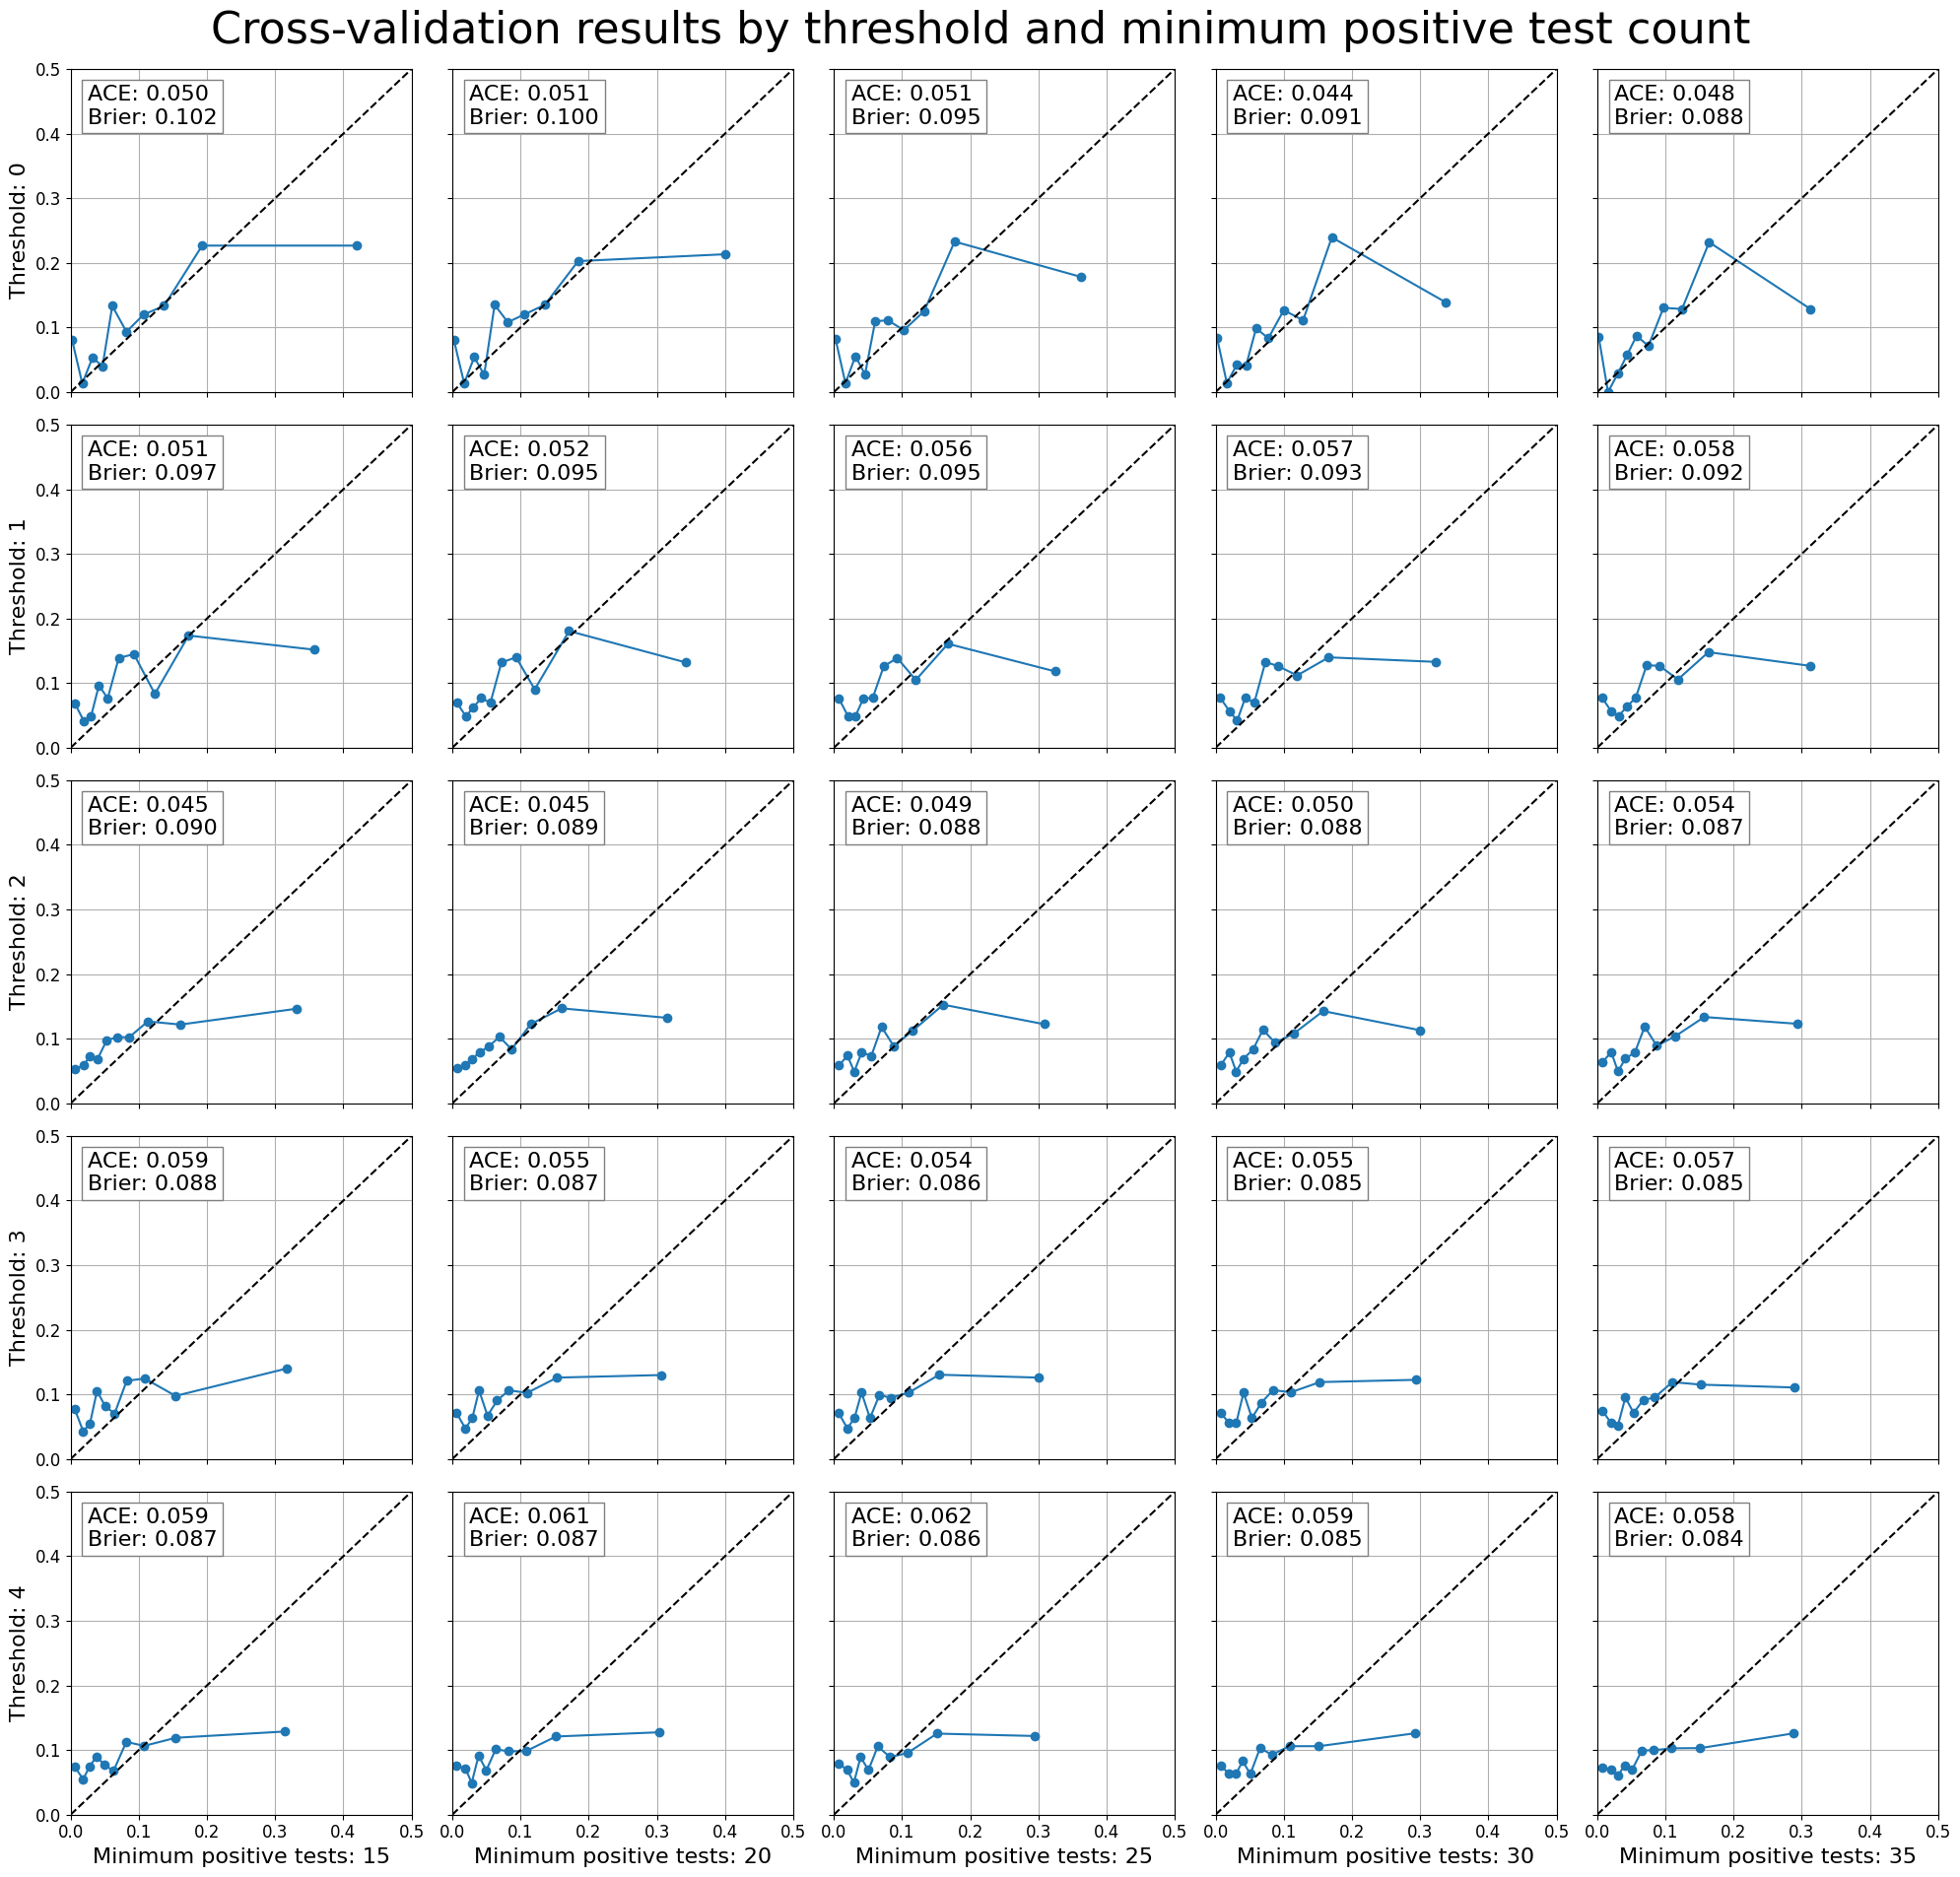

In [25]:
datasets = sorted(df_crossval_results["dataset"].unique())
window_sizes = sorted(df_crossval_results["window_size"].unique())

n_rows = len(datasets)
n_cols = len(window_sizes)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows), sharex=True, sharey=True)

for i, dataset in enumerate(datasets):
    for j, window_size in enumerate(window_sizes):
        ax = axes[i, j] if n_rows > 1 else axes[j]

        # Filter the corresponding row in df_crossval_results
        row = df_crossval_results[(df_crossval_results["dataset"] == dataset) & (df_crossval_results["window_size"] == window_size)]

        if row.empty:
            ax.axis('off')  # Hide axes if data missing
            continue

        mean_pred = np.array(json.loads(row.iloc[0]["mean_predicted_values"]))
        frac_pos = np.array(json.loads(row.iloc[0]["fraction_of_positives"]))
        ace = row.iloc[0]["ACE"]
        brier = row.iloc[0]["BrierScore"]
        avg_window_size = round(row.iloc[0]["avg_window_size"], 1)

        # Plot calibration curve and reference line
        ax.plot(mean_pred, frac_pos, "o-", label="Model")
        ax.plot([0, 1], [0, 1], "k--", label="Perfect Calibration")

        # Add annotations for ACE and Brier Score
        ax.text(0.05, 0.95, f"ACE: {ace:.3f}\nBrier: {brier:.3f}",
                transform=ax.transAxes, fontsize=16,
                verticalalignment='top', bbox=dict(facecolor='white', alpha=1, edgecolor='gray'))

        # Label x-axis only for bottom row, y-axis only for first column
        if i == n_rows - 1:
            ax.set_xlabel(f"Minimum positive tests: {window_size}", fontsize=16)
        if j == 0:
            ax.set_ylabel(f"Threshold: {dataset[-1]}", fontsize=16)

        # Only show legend on the first subplot
        #if i == 0 and j == 0:
        #    ax.legend(loc="center left", fontsize=14, framealpha=1)

        ax.set_xlim(0, 0.5)
        ax.set_ylim(0, 0.5)
        ax.tick_params(axis='both', labelsize=12)
        ax.grid(True)

plt.suptitle("Cross-validation results by threshold and minimum positive test count", fontsize=32)
plt.tight_layout(rect=[0, 0.03, 1, 0.99])
plt.savefig("calibration_grid_adaptive_window.png", dpi=200, bbox_inches='tight')  # PNG at 600 DPI
#plt.savefig("calibration_grid.pdf", bbox_inches='tight')
plt.show()

In [31]:
df_risk = risk_mle_adaptive_triangle_only_pos(df_behavior=df_max2, min_pos_tests=20, max_window_size=63, Poisson_contacts = False)

In [33]:
df_pred = predict_postest(df_risk, df_max2)

2195it [00:01, 1445.16it/s]


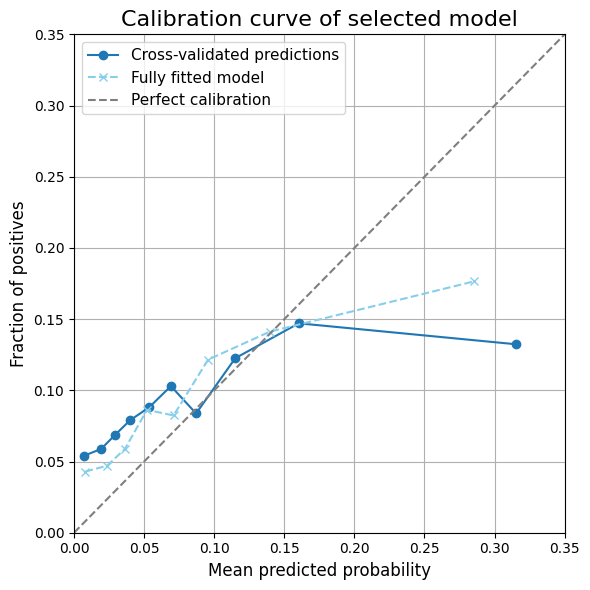

In [35]:
# First curve: from cross-validation
mean_predicted_value_1 = np.array(json.loads(df_crossval_results["mean_predicted_values"][11]))
fraction_of_positives_1 = np.array(json.loads(df_crossval_results["fraction_of_positives"][11]))

# Second curve: from fitted model
y_true = df_pred['positivetest']
y_prob = df_pred['predicted_infections']
fraction_of_positives_2, mean_predicted_value_2 = calibration_curve(y_true, y_prob, n_bins=8, strategy="quantile")

# Plot both on the same figure
plt.figure(figsize=(6, 6))
plt.plot(mean_predicted_value_1, fraction_of_positives_1, "o-", color="tab:blue",
         label="Cross-validated predictions")
plt.plot(mean_predicted_value_2, fraction_of_positives_2, "x--", color="skyblue",
         label="Fully fitted model")

# Reference line for perfect calibration
plt.plot([0, 1], [0, 1], "--", color="tab:gray", label="Perfect calibration")

# Labels and limits
plt.xlabel("Mean predicted probability", size=12)
plt.ylabel("Fraction of positives", size=12)
plt.title("Calibration curve of selected model", size=16)
plt.xlim(0, 0.35)
plt.ylim(0, 0.35)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()
plt.show()

In [37]:
def smoothed_predictions_plot(df, window_size):
    
    df["T0_date"] = pd.to_datetime(df["T0_date"])

    # Step 1: Aggregate daily counts
    daily = df.groupby("T0_date")[["predicted_infections", "positivetest"]].sum()

    # Step 3: Apply moving average (centered)
    smoothed = daily.rolling(window=window_size, center=True).mean()

    # Step 4: Drop NaNs caused by the smoothing window
    smoothed = smoothed.dropna()

    # Step 5: Plot
    plt.figure(figsize=(12, 6))
    plt.plot(smoothed.index, smoothed["positivetest"],
             label=f"Actual Positive Tests ({window_size}-day MA)", color='tab:blue')
    plt.plot(smoothed.index, smoothed["predicted_infections"],
             label=f"Predicted Positive Tests ({window_size}-day MA)", color='tab:orange')

    ax = plt.gca()
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    
    plt.title("21-Day Moving Average of Actual vs Predicted Positive Tests Per Day", size=16)
    plt.xlim(smoothed["predicted_infections"].index.min(), smoothed["predicted_infections"].index.max())
    plt.ylim(0, 1.5)
    plt.xlabel("Date", size=12)
    plt.ylabel("Number of Positive Tests", size=12)
    plt.xticks(rotation=45, ha='right')
    plt.legend(loc="upper left", fontsize=11)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

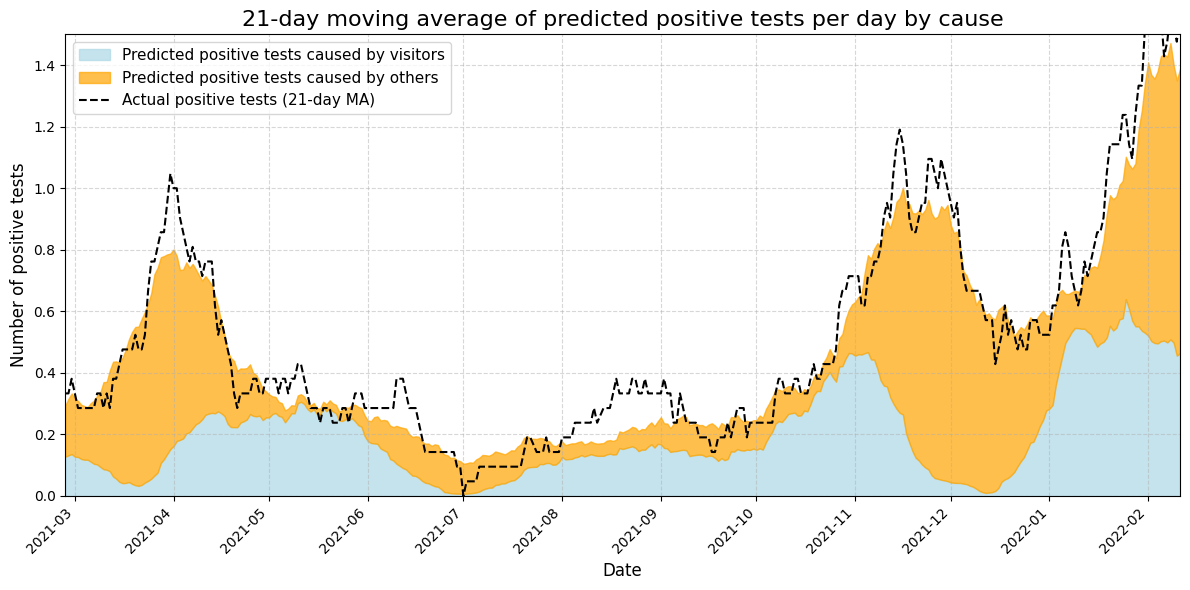

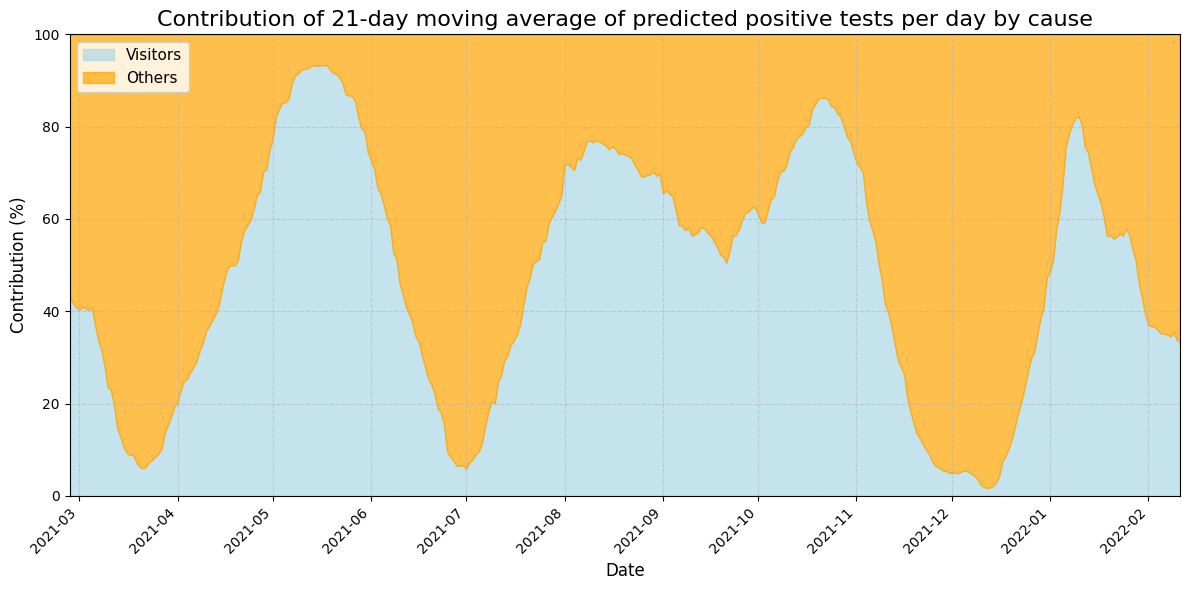

In [39]:
plot_cause_split(df_pred, window_size=21)
plot_cause_split_proportions(df_pred, window_size=21)

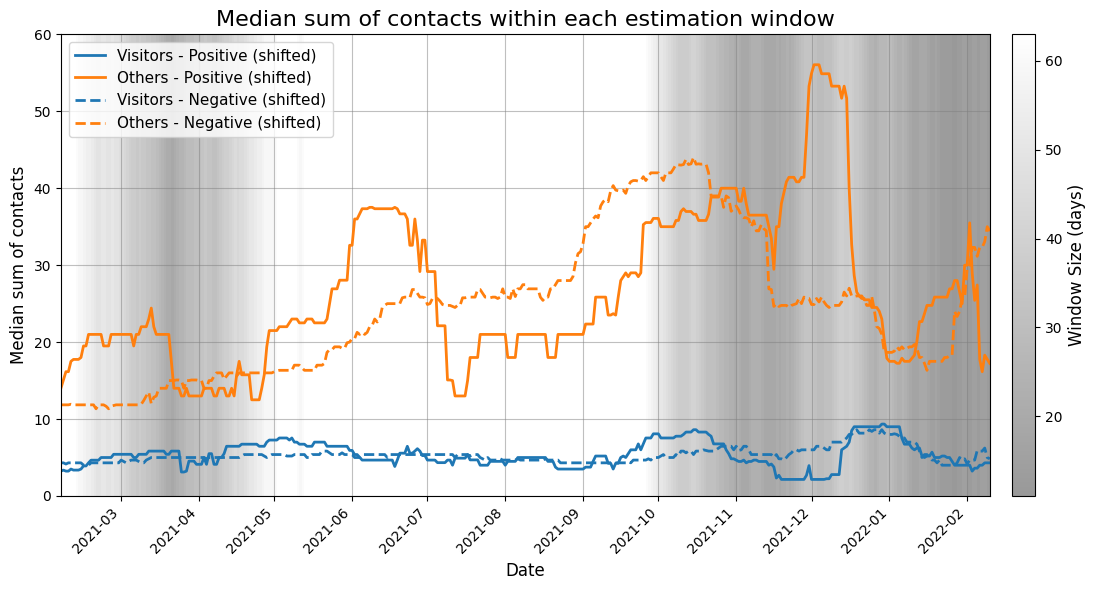

In [41]:
# Ensure datetime format
df_max2['T0_date'] = pd.to_datetime(df_max2['T0_date'])
df_risk['T0_date'] = pd.to_datetime(df_risk['T0_date'])

# Filter only where full_window_used is True
df_risk_filtered = df_risk[df_risk['full_window_used'] == True].copy()

# Shift T0 dates for alignment
df_risk_filtered['shifted_T0_date'] = df_risk_filtered['T0_date'] - pd.to_timedelta(11, unit='D')

# Create normalized colormap with alpha
norm = mcolors.Normalize(vmin=df_risk_filtered['window_size_days'].min(),
                         vmax=df_risk_filtered['window_size_days'].max())
viridis = plt.colormaps['gist_gray']
viridis_with_alpha = viridis(np.linspace(0, 1, 256))
viridis_with_alpha[:, -1] = 0.4  # Set alpha
cmap_with_alpha = ListedColormap(viridis_with_alpha)

# Collect median values per window
records = []
for _, row in df_risk_filtered.iterrows():
    t0 = row['T0_date']
    half_window = pd.Timedelta(days=row['window_size_days'] / 2)
    start = t0 - half_window
    end = t0 + half_window

    df_window = df_max2[(df_max2['T0_date'] >= start) & (df_max2['T0_date'] <= end)]

    df_pos = df_window[df_window['positivetest'] == 1]
    df_neg = df_window[df_window['positivetest'] == 0]

    records.append({
        'shifted_T0_date': row['shifted_T0_date'],  # Shifted date used for plotting
        'visitors_pos': df_pos['sum_visitors_t1_t11_interpolated'].median(),
        'others_pos': df_pos['sum_others_t1_t11_interpolated'].median(),
        'visitors_neg': df_neg['sum_visitors_t1_t11_interpolated'].median(),
        'others_neg': df_neg['sum_others_t1_t11_interpolated'].median()
    })

# Create DataFrame
df_window_medians = pd.DataFrame(records)

# === Plot ===
fig, ax = plt.subplots(figsize=(12, 6))

# Add background shading
for _, row in df_risk_filtered.iterrows():
    ax.axvspan(
        row['shifted_T0_date'],
        row['shifted_T0_date'] + pd.Timedelta(days=1),
        color=cmap_with_alpha(norm(row['window_size_days'])),
        linewidth=0
    )

# Plot median contact values
ax.plot(df_window_medians['shifted_T0_date'], df_window_medians['visitors_pos'],
        label='Visitors - Positive (shifted)', color='tab:blue', linewidth=2)
ax.plot(df_window_medians['shifted_T0_date'], df_window_medians['others_pos'],
        label='Others - Positive (shifted)', color='tab:orange', linewidth=2)
ax.plot(df_window_medians['shifted_T0_date'], df_window_medians['visitors_neg'],
        label='Visitors - Negative (shifted)', color='tab:blue', linestyle='--', linewidth=2)
ax.plot(df_window_medians['shifted_T0_date'], df_window_medians['others_neg'],
        label='Others - Negative (shifted)', color='tab:orange', linestyle='--', linewidth=2)

# Axis formatting
ax.set_xlim(df_window_medians['shifted_T0_date'].min(), df_window_medians['shifted_T0_date'].max())
ax.set_ylim(0, 60)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.set_title('Median sum of contacts within each estimation window', size=16)
ax.set_xlabel('Date', size=12)
ax.set_ylabel('Median sum of contacts', size=12)
ax.legend(loc="upper left", fontsize=11)
ax.grid(True, c="gray", alpha=0.5)
plt.xticks(rotation=45, ha='right')

# Add colorbar
sm = ScalarMappable(cmap=cmap_with_alpha, norm=norm)
sm.set_array(df_risk_filtered['window_size_days'])
cbar = plt.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label('Window Size (days)', size=12)

plt.tight_layout()
plt.show()

# Estimates and confidence intervals for estimated risk per contact



In [43]:
def bootstrap_confidence_intervals_pred(df_behavior, min_pos_tests, max_window_size, n_bootstraps=100, alpha=0.05):
    """
    Return point estimates and bootstrap confidence intervals for epsilon and gamma per T0_date
    using Poisson bootstrapping and adaptive windowing.

    1. Calculate the base results (This also saves the needed window size per test date)
2. Loop over all dates and collect all tests which fall within the adaptive window for that date
3.     Repeat "n_bootstrap" times:
4.         Sample for each test in the window a number of visitors and other contacts based on Poisson distributions using the actual value as                    the parameter of said Poisson distribution
6.      Calculate and save the 95% CI for this date
    
    """
    np.random.seed(1809)
    
    base_results = risk_mle_adaptive_triangle_only_pos(df_behavior, min_pos_tests, max_window_size)
    ci_results = []
    ci_results_pred = []
    
    df_samples_epsilon = pd.DataFrame()
    df_samples_gamma = pd.DataFrame()
    df_samples_daily_predicted = pd.DataFrame()
    df_samples_vis_infections = pd.DataFrame()
    df_samples_oth_infections = pd.DataFrame()

    for sample_nr in tqdm(range(n_bootstraps), desc = 'Bootstrap iteration'):
        #print('Bootstrap sample', sample_nr)
        df_risk_HELP = risk_mle_adaptive_triangle_only_pos(df_behavior, min_pos_tests, max_window_size, Poisson_contacts = True)
        df_samples_epsilon[str(sample_nr)] = df_risk_HELP['estimated_epsilon']
        df_samples_gamma[str(sample_nr)] = df_risk_HELP['estimated_gamma']
        df_pred_HELP = predict_postest(df_risk_HELP, df_behavior)
        
        daily_predicted_infections = df_pred_HELP.groupby("T0_date")["predicted_infections"].sum()
        daily_vis_infections = df_pred_HELP.groupby("T0_date")["vis_ratio_split"].sum()
        daily_oth_infections = df_pred_HELP.groupby("T0_date")["oth_ratio_split"].sum()
        daily_actual_infections = df_pred_HELP.groupby("T0_date")["positivetest"].sum()
        
        window_size = 21
        predicted_ma = daily_predicted_infections.rolling(window=window_size, center=True).mean()
        vis_ma = daily_vis_infections.rolling(window=window_size, center=True).mean()
        oth_ma = daily_oth_infections.rolling(window=window_size, center=True).mean()
        actual_ma = daily_actual_infections.rolling(window=window_size, center=True).mean()

        predicted_ma = predicted_ma.dropna()
        vis_ma = vis_ma.dropna()
        oth_ma = oth_ma.dropna()
        actual_ma = actual_ma.dropna()
        
        df_samples_daily_predicted[str(sample_nr)] = predicted_ma#daily_predicted_infections
        df_samples_vis_infections[str(sample_nr)] = vis_ma#daily_vis_infections
        df_samples_oth_infections[str(sample_nr)] = oth_ma#daily_oth_infections
        
        

    for _, row in tqdm(base_results.iterrows(), total=len(base_results), desc="Bootstrapping CIs"):
        date = row["T0_date"]
        # Compute confidence interval percentiles
        lower = alpha / 2
        upper = 1 - alpha / 2


        ci_results.append({
                "T0_date": date,
                "estimated_epsilon": row["estimated_epsilon"],
                "estimated_gamma": row["estimated_gamma"],
                "window_size_days": row["window_size_days"],
                "max_window_reached": row["max_window_reached"],
                "full_window_used": row["full_window_used"]
        })
        
    df_ci_results = pd.DataFrame(ci_results).sort_values("T0_date").reset_index(drop=True)
    new_columns = {'epsilon_lower': df_samples_epsilon.quantile(lower,axis = 1), 
                   'epsilon_upper': df_samples_epsilon.quantile(upper, axis = 1), 
                   'gamma_lower': df_samples_gamma.quantile(lower, axis = 1), 
                   'gamma_upper': df_samples_gamma.quantile(upper, axis = 1),
                  }
    print(new_columns)
    df_ci_results = df_ci_results.assign(**new_columns)
    
    pred_columns = {'predicted_lower': df_samples_daily_predicted.quantile(lower, axis = 1),
                    'predicted_upper': df_samples_daily_predicted.quantile(upper, axis = 1),
                    'vis_lower': df_samples_vis_infections.quantile(lower, axis = 1),
                    'vis_upper': df_samples_vis_infections.quantile(upper, axis = 1),
                    'oth_lower': df_samples_oth_infections.quantile(lower, axis = 1),
                    'oth_upper': df_samples_oth_infections.quantile(upper, axis = 1),  
                    'actual': daily_actual_infections,
                    'actual_ma': actual_ma,
                   }
    df_ci_results_predict = pd.DataFrame(pred_columns).sort_values("T0_date").reset_index(drop = False)
                    
        #return pd.DataFrame(ci_results).sort_values("T0_date").reset_index(drop=True)
    return df_ci_results, df_ci_results_predict

In [45]:
test_output = bootstrap_confidence_intervals_pred(df_max2, 20, 63, n_bootstraps = 100)
df_ci = test_output[0]
df_ci_pred = test_output[1]
df_ci.to_csv("data/ci_100.csv",index = False)
df_ci_pred.to_csv("data/ci_100_pred.csv",index = False)

Bootstrap iteration:   0%|                                                                     | 0/100 [00:00<?, ?it/s]
0it [00:00, ?it/s]
156it [00:00, 1542.54it/s]
311it [00:00, 1541.05it/s]
466it [00:00, 1442.62it/s]
615it [00:00, 1459.31it/s]
762it [00:00, 1423.21it/s]
910it [00:00, 1439.26it/s]
1073it [00:00, 1496.41it/s]
1223it [00:00, 1450.13it/s]
1373it [00:00, 1459.52it/s]
1520it [00:01, 1207.28it/s]
1650it [00:01, 1228.91it/s]
1781it [00:01, 1244.88it/s]
1926it [00:01, 1296.38it/s]
2059it [00:01, 1288.07it/s]
2195it [00:01, 1341.11it/s]
Bootstrap iteration:   1%|▌                                                          | 1/100 [00:59<1:38:05, 59.45s/it]
0it [00:00, ?it/s]
147it [00:00, 1463.53it/s]
301it [00:00, 1501.28it/s]
462it [00:00, 1547.91it/s]
617it [00:00, 1475.59it/s]
766it [00:00, 1433.21it/s]
910it [00:00, 1356.80it/s]
1064it [00:00, 1409.06it/s]
1219it [00:00, 1447.99it/s]
1365it [00:00, 1407.56it/s]
1507it [00:01, 1271.96it/s]
1637it [00:01, 1267.00it/s]
1766it

{'epsilon_lower': 0      1.000000e-10
1      1.000000e-10
2      1.000000e-10
3      1.000000e-10
4      1.000000e-10
           ...     
405    4.696732e-02
406    3.232812e-02
407    1.000000e-10
408    1.000000e-10
409    1.000000e-10
Name: 0.025, Length: 410, dtype: float64, 'epsilon_upper': 0      1.000000e-10
1      1.610061e-02
2      1.322603e-02
3      1.188162e-02
4      8.345348e-03
           ...     
405    8.005087e-02
406    6.632310e-02
407    2.814330e-02
408    1.786631e-02
409    1.000000e-10
Name: 0.975, Length: 410, dtype: float64, 'gamma_lower': 0      1.000000e-10
1      1.000000e-10
2      1.000000e-10
3      1.000000e-10
4      1.000000e-10
           ...     
405    5.018078e-03
406    3.635640e-03
407    1.139809e-02
408    7.938969e-03
409    1.000000e-10
Name: 0.025, Length: 410, dtype: float64, 'gamma_upper': 0      1.000000e-10
1      6.325285e-03
2      4.026527e-03
3      3.451301e-03
4      2.039772e-03
           ...     
405    1.281142e-02
406    1.

In [49]:
df_ci = pd.read_csv("data/ci_100.csv")
df_ci['T0_date'] = pd.to_datetime(df_ci['T0_date'])

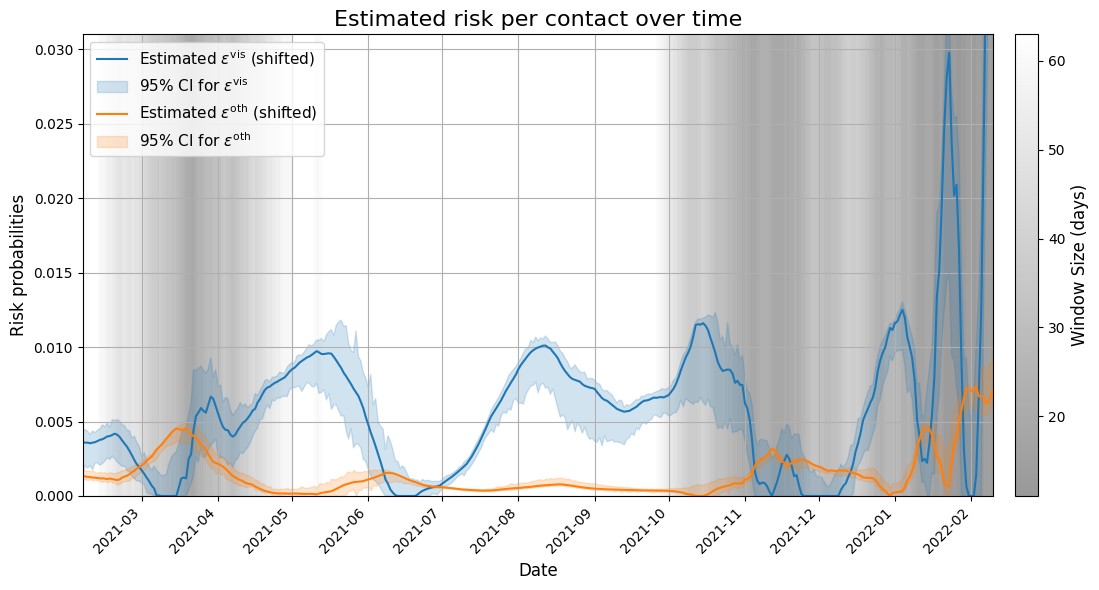

In [51]:
# Only use rows where full window was used
df_plot = df_ci[df_ci["full_window_used"] == 1].copy()

# Shift T0 dates for x-axis
df_plot["shifted_T0_date"] = df_plot["T0_date"] - pd.to_timedelta(11, unit='D')

# Only plot the dates where the full window was used
df_risk_clean = df_risk[df_risk['full_window_used'] == 1].copy()

# Shift T0 dates by 11 days earlier
df_risk_clean['shifted_T0_date'] = df_risk_clean['T0_date'] - pd.to_timedelta(11, unit='D')


# Normalize window size values for colormap scaling
norm = mcolors.Normalize(vmin=df_risk_clean['window_size_days'].min(),
                         vmax=df_risk_clean['window_size_days'].max())

# Create transparent version of viridis colormap
alpha = 0.4
viridis = plt.colormaps['gist_gray']
viridis_with_alpha = viridis(np.linspace(0, 1, 256))
viridis_with_alpha[:, -1] = alpha  # Set alpha in RGBA
cmap_with_alpha = ListedColormap(viridis_with_alpha)

plt.figure(figsize=(12, 6))

# Plot full-height background color spans using window size as color
for i, row in df_risk_clean.iterrows():
    plt.axvspan(
        row['shifted_T0_date'],
        row['shifted_T0_date'] + pd.Timedelta(days=1),  # one-day span
        color=cmap_with_alpha(norm(row['window_size_days'])),
        linewidth=0
    )

# === Epsilon ===
plt.plot(df_plot["shifted_T0_date"], df_plot["estimated_epsilon"], label=r'Estimated $\epsilon^{\mathrm{vis}}$ (shifted)', color="tab:blue")
plt.fill_between(df_plot["shifted_T0_date"], df_plot["epsilon_lower"], df_plot["epsilon_upper"],
                 color="tab:blue", alpha=0.2, label=r"95% CI for $\epsilon^{\mathrm{vis}}$")

# === Gamma ===
plt.plot(df_plot["shifted_T0_date"], df_plot["estimated_gamma"], label=r'Estimated $\epsilon^{\mathrm{oth}}$ (shifted)', color="tab:orange")
plt.fill_between(df_plot["shifted_T0_date"], df_plot["gamma_lower"], df_plot["gamma_upper"],
                 color="tab:orange", alpha=0.2, label=r"95% CI for $\epsilon^{\mathrm{oth}}$")


# Formatting
plt.xlim(df_plot["shifted_T0_date"].min(), df_plot["shifted_T0_date"].max())
plt.ylim(0, 0.031)


ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator())
plt.xticks(rotation=45, ha='right')

# Add colorbar to show the window size encoding (with alpha)
sm = ScalarMappable(cmap=cmap_with_alpha, norm=norm)
sm.set_array(df_risk_clean['window_size_days'])
cbar = plt.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label('Window Size (days)', size=12)




plt.title("Estimated risk per contact over time", fontsize=16)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Risk probabilities", fontsize=12)
plt.legend(loc="upper left", fontsize=11)
plt.grid(True)
plt.tight_layout()
plt.show()

In [53]:
def smoothed_predictions_plot_CI(df, df_ci, df_ci_predict, window_size):
    
    #ONly if df_ci_predict contains date!
    df["T0_date"] = pd.to_datetime(df["T0_date"])
    df_ci_predict['T0_date'] = pd.to_datetime(df_ci_predict['T0_date'])
    
    # Only use rows where full window was used
    df_plot = df_ci_predict
    
    # Step 1: Aggregate daily counts
    daily = df.groupby("T0_date")[["predicted_infections", "positivetest","vis_only","oth_only"]].sum()

    # Step 3: Apply moving average (centered)
    smoothed = daily.rolling(window=window_size, center=True).mean()
    smoothed_CI = (df_plot.set_index('T0_date')).rolling(window=window_size,center=True).mean()
    
    # Step 4: Drop NaNs caused by the smoothing window
    smoothed = smoothed.dropna()
    print(smoothed)
    print(df_plot)
    smoothed_CI = smoothed_CI.dropna()
    df_plot = df_plot.dropna()

    df_plot['T0_date'] = smoothed.index
    # Step 5: Plot
    plt.figure(figsize=(12, 6))
    plt.plot(smoothed.index, smoothed["vis_only"],
             label=f"Predicted positive tests caused by visitors", color='tab:blue')
    plt.fill_between(df_plot['T0_date'],df_plot["vis_lower"], df_plot["vis_upper"],
                 color="tab:blue", alpha=0.2, label=r"_95% CI for positive tests caused by visitors")
    plt.plot(smoothed.index, smoothed["oth_only"],
             label=f"Predicted positive tests caused by others", color='tab:orange')
    plt.fill_between(df_plot['T0_date'],df_plot["oth_lower"], df_plot["oth_upper"],
                 color="tab:orange", alpha=0.2, label=r"_95% CI for positive tests caused by others")
    #plt.plot(df_plot['shifted_T0_date'],df_plot['actual_ma'])
    
    #Quick fix for paper: calculate correlation coefficient:
    print('Correlation is', smoothed['positivetest'].corr(smoothed["predicted_infections"]))
    
    ax = plt.gca()
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    
    plt.title("21-day moving average of predicted positive tests per day by cause", size=16)
    plt.xlim(smoothed["predicted_infections"].index.min(), smoothed["predicted_infections"].index.max())
    plt.ylim(0, 1.5)
    plt.xlabel("Date", size=12)
    plt.ylabel("Number of positive tests", size=12)
    plt.xticks(rotation=45, ha='right')
    plt.legend(loc="upper left", fontsize=11)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [55]:
df_ci_predict = pd.read_csv("data/ci_100_pred.csv")
df_ci_predict['T0_date'] = pd.to_datetime(df_ci_predict['T0_date'])

In [57]:
df_pred.groupby("T0_date")[["predicted_infections", "positivetest"]].sum()

,predicted_infections,positivetest
T0_date,,
2021-02-16,0.067473,0
2021-02-17,0.071267,0
2021-02-18,0.383298,1
2021-02-19,0.467801,1
2021-02-20,0.587846,0
...,...,...
2022-02-17,0.765355,1
2022-02-18,2.584274,3
2022-02-19,0.851477,2


            predicted_infections  positivetest  vis_only  oth_only
T0_date                                                           
2021-02-26              0.294373      0.333333  0.122035  0.163699
2021-02-27              0.315942      0.333333  0.126267  0.180614
2021-02-28              0.333063      0.380952  0.130165  0.193561
2021-03-01              0.317186      0.333333  0.121943  0.186243
2021-03-02              0.308951      0.285714  0.120961  0.179194
...                          ...           ...       ...       ...
2022-02-07              1.427163      1.476190  0.470512  0.904046
2022-02-08              1.471877      1.571429  0.470672  0.934407
2022-02-09              1.400388      1.523810  0.464669  0.871338
2022-02-10              1.350137      1.476190  0.421962  0.864684
2022-02-11              1.388030      1.571429  0.427290  0.890705

[347 rows x 4 columns]
       T0_date  predicted_lower  predicted_upper  vis_lower  vis_upper  \
0   2021-02-16              NaN

C:\Users\danic\AppData\Local\Temp\ipykernel_9948\2100071935.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot['T0_date'] = smoothed.index


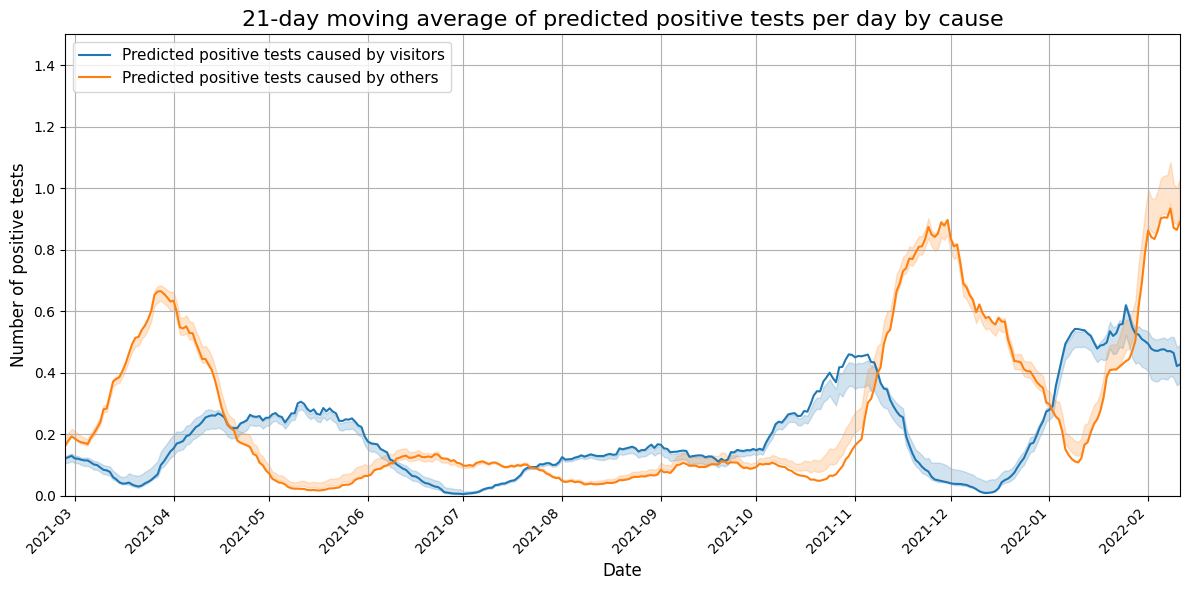

In [59]:
smoothed_predictions_plot_CI(df_pred, df_ci, df_ci_predict, 21)

# Calculations for unbounded risk, may be removed?

Fitting adaptive MLE:   1%|▌                                                           | 4/410 [00:00<00:15, 25.60it/s]C:\Users\danic\AppData\Local\Temp\ipykernel_9948\1190644227.py:11: RuntimeWarning: overflow encountered in scalar power
  P_t = 1 - (1 - epsilon)**n_vis_t * (1 - gamma)**n_oth_t
C:\Users\danic\AppData\Local\Temp\ipykernel_9948\1190644227.py:11: RuntimeWarning: overflow encountered in scalar power
  P_t = 1 - (1 - epsilon)**n_vis_t * (1 - gamma)**n_oth_t
C:\Users\danic\AppData\Local\Temp\ipykernel_9948\1190644227.py:11: RuntimeWarning: overflow encountered in scalar power
  P_t = 1 - (1 - epsilon)**n_vis_t * (1 - gamma)**n_oth_t
Fitting adaptive MLE:   2%|█                                                           | 7/410 [00:00<00:38, 10.58it/s]C:\Users\danic\AppData\Local\Temp\ipykernel_9948\1190644227.py:11: RuntimeWarning: overflow encountered in scalar power
  P_t = 1 - (1 - epsilon)**n_vis_t * (1 - gamma)**n_oth_t
Fitting adaptive MLE:  80%|███████████████████████

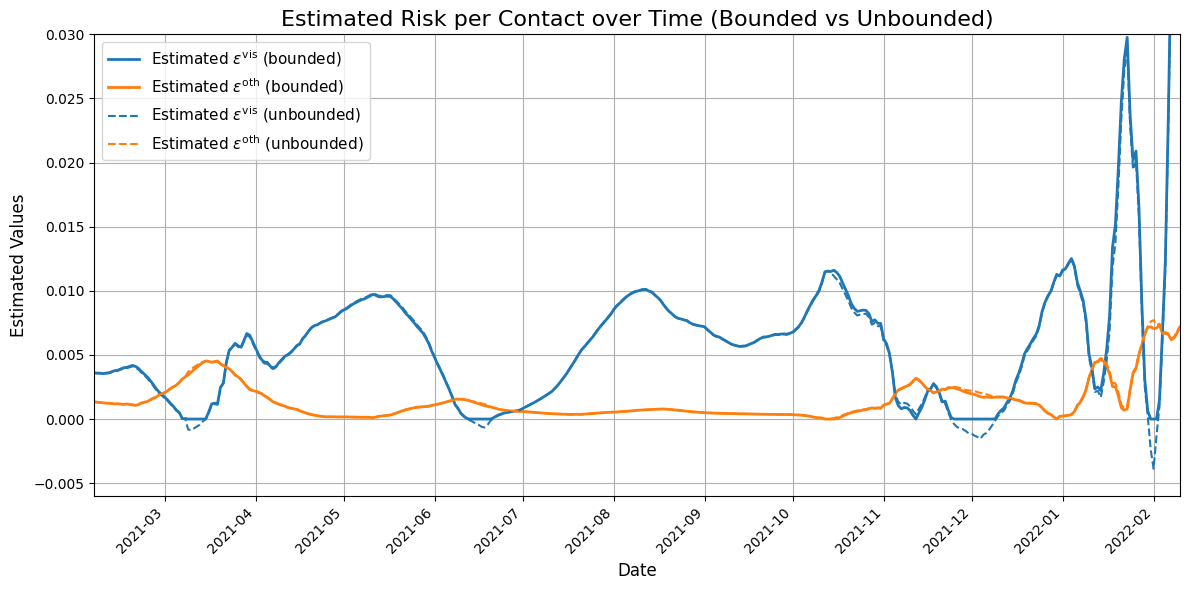

In [68]:
df_max2_rounded = df_max2.copy()
df_max2_rounded["sum_visitors_t1_t11_interpolated"] = df_max2_rounded['sum_visitors_t1_t11_interpolated'].round().astype(int)
df_max2_rounded["sum_others_t1_t11_interpolated"] = df_max2_rounded['sum_others_t1_t11_interpolated'].round().astype(int)
df_risk_unbounded = risk_no_bounds(df_max2_rounded, 20, 63)

# Clean the data
df_risk_clean = df_risk[df_risk['full_window_used'] == 1].copy()
df_risk_clean['shifted_T0_date'] = df_risk_clean['T0_date'] - pd.to_timedelta(11, unit='D')

df_risk_unbounded_clean = df_risk_unbounded[df_risk_unbounded['full_window_used'] == 1].copy()
df_risk_unbounded_clean['shifted_T0_date'] = df_risk_unbounded_clean['T0_date'] - pd.to_timedelta(11, unit='D')

# Create figure
plt.figure(figsize=(12, 6))

# === Bounded estimates ===
plt.plot(df_risk_clean['shifted_T0_date'], df_risk_clean['estimated_epsilon'],
         label=r'Estimated $\epsilon^{\mathrm{vis}}$ (bounded)', 
         color="tab:blue", linestyle='-', linewidth=2)

plt.plot(df_risk_clean['shifted_T0_date'], df_risk_clean['estimated_gamma'],
         label=r'Estimated $\epsilon^{\mathrm{oth}}$ (bounded)', 
         color="tab:orange", linestyle='-', linewidth=2)
, linewidth=2
# === Unbounded estimates ===
plt.plot(df_risk_unbounded_clean['shifted_T0_date'], df_risk_unbounded_clean['estimated_epsilon'],
         label=r'Estimated $\epsilon^{\mathrm{vis}}$ (unbounded)', linewidth=1.5, 
         color="tab:blue", linestyle='--')

plt.plot(df_risk_unbounded_clean['shifted_T0_date'], df_risk_unbounded_clean['estimated_gamma'],
         label=r'Estimated $\epsilon^{\mathrm{oth}}$ (unbounded)', linewidth=1.5, 
         color="tab:orange", linestyle='--')

# Formatting
plt.xlim(min(df_risk_clean['shifted_T0_date'].min(), df_risk_unbounded_clean['shifted_T0_date'].min()),
         max(df_risk_clean['shifted_T0_date'].max(), df_risk_unbounded_clean['shifted_T0_date'].max()))

plt.ylim(-0.006, 0.03)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator())
plt.xticks(rotation=45, ha='right')

plt.title('Estimated Risk per Contact over Time (Bounded vs Unbounded)', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Estimated Values', fontsize=12)
plt.legend(loc="upper left", fontsize=11)
plt.grid(True)
plt.tight_layout()
plt.show()

# Selecting best settings for simple model and comparing the fit to original model

In [72]:
def log_likelihood_simple_weighted(params, I_t_input, n_vis, n_oth, weights):
    epsilon = params[0]  # single parameter

    log_likelihood_value = 0

    for t in range(len(I_t_input)):
        I_t = I_t_input[t]
        n_vis_t = n_vis[t]
        n_oth_t = n_oth[t]
        w_t = weights[t]

        # Combined contact effect
        P_t = 1 - (1 - epsilon)**(n_vis_t + n_oth_t)
        P_t = np.clip(P_t, 1e-10, 1 - 1e-10)

        log_likelihood_value += w_t * (I_t * np.log(P_t) + (1 - I_t) * np.log(1 - P_t))

    return -log_likelihood_value

In [74]:
def cross_validation_adaptive_window_simple(df, min_pos_tests, max_window_size_days):
    
    kf = KFold(n_splits=10, shuffle=True, random_state=1809)
    df = df.copy()
    df["T0_date"] = pd.to_datetime(df["T0_date"])

    all_predictions = []
    all_actuals = []
    all_window_sizes = []
    max_window_hit_flags = []
    pos_tests_used = []

    fold = 1

    for train_idx, val_idx in kf.split(df):
        print(f"Processing Fold {fold}")
        train_df = df.iloc[train_idx].copy()
        val_df = df.iloc[val_idx].copy()
        train_results = []

        all_dates = train_df["T0_date"].sort_values().unique()
        min_date = all_dates.min()
        max_date = all_dates.max()

        full_date_range = pd.date_range(start=min_date, end=max_date)

        for date in full_date_range:
            date = pd.Timestamp(date)
            left_offset = 0
            right_offset = 0
            total_tests = 0
            pos_tests = 0
            boundary_hit = False
            max_hit = False

            while pos_tests < min_pos_tests:
                start_date = date - timedelta(days=left_offset)
                end_date = date + timedelta(days=right_offset)

                current_window_size = (end_date - start_date).days + 1

                if start_date < min_date or end_date > max_date:
                    boundary_hit = True
                    break

                if current_window_size >= max_window_size_days:
                    max_hit = True
                    break

                window_data = train_df[
                    (train_df["T0_date"] >= start_date) & (train_df["T0_date"] <= end_date)
                ].copy()

                total_tests = len(window_data)
                pos_tests = len(window_data[window_data["positivetest"] == 1])
                left_offset += 1
                right_offset += 1

            if total_tests == 0:
                continue

            current_window_size = (end_date - start_date).days + 1
            
            window_data["day_offset"] = (pd.to_datetime(window_data["T0_date"]) - pd.to_datetime(date)).dt.days
            max_offset = max(abs(window_data["day_offset"].min()), abs(window_data["day_offset"].max()))
            window_size = 2 * max_offset + 1
            window_data["day_weight"] = (window_size + 1) / 2 - window_data["day_offset"].abs()

            weights = np.array(window_data["day_weight"])
            I_t = np.array(window_data["positivetest"])
            n_vis = np.array(window_data["sum_visitors_t1_t11_interpolated"])
            n_oth = np.array(window_data["sum_others_t1_t11_interpolated"])

            initial_guess = [0.001]
            
            result = minimize(
                log_likelihood_simple_weighted,
                initial_guess,
                args=(I_t, n_vis, n_oth, weights),
                bounds=[(1e-10, 1 - 1e-10)],
            )

            epsilon_hat = result.x[0]

            train_results.append({
                "T0_date": date,
                "estimated_epsilon": epsilon_hat,
                "window_size": current_window_size,
                "full_window_used": not boundary_hit
            })

        train_estimates = pd.DataFrame(train_results)

        predictions = []
        actuals = []
        val_window_sizes = []
        val_max_flags = []
        val_pos_tests = []

        for _, row in val_df.iterrows():
            date = row["T0_date"]
            epsilon_gamma = train_estimates[
                (train_estimates["T0_date"] == date) & (train_estimates["full_window_used"] == True)
            ]

            if epsilon_gamma.empty:
                predictions.append(np.nan)
                actuals.append(np.nan)
                val_window_sizes.append(np.nan)
                val_max_flags.append(np.nan)
                val_pos_tests.append(np.nan)
                continue

            epsilon = epsilon_gamma["estimated_epsilon"].values[0]
            n_vis = row["sum_visitors_t1_t11_interpolated"]
            n_oth = row["sum_others_t1_t11_interpolated"]
            P_t = 1 - (1 - epsilon) ** (n_vis + n_oth)

            predictions.append(P_t)
            actuals.append(row["positivetest"])
            current_size = epsilon_gamma["window_size"].values[0]
            val_window_sizes.append(current_size)
            val_max_flags.append(current_size >= max_window_size_days)
            val_pos_tests.append(min_pos_tests)

        val_df["predicted_infections"] = predictions

        val_actuals = np.array(val_df["positivetest"])
        val_predictions = np.array(val_df["predicted_infections"])

        valid_mask = ~np.isnan(val_actuals) & ~np.isnan(val_predictions)
        val_actuals = val_actuals[valid_mask]
        val_predictions = val_predictions[valid_mask]
        val_window_sizes = np.array(val_window_sizes)[valid_mask]
        val_max_flags = np.array(val_max_flags)[valid_mask]
        val_pos_tests = np.array(val_pos_tests)[valid_mask]

        all_predictions.extend(val_predictions)
        all_actuals.extend(val_actuals)
        all_window_sizes.extend(val_window_sizes)
        max_window_hit_flags.extend(val_max_flags)
        pos_tests_used.extend(val_pos_tests)

        df.loc[val_df.index[valid_mask], 'predicted_infections'] = val_predictions
        fold += 1

    df_clean = df[df["predicted_infections"].notna()]
    y_true = df_clean['positivetest']
    y_prob = df_clean['predicted_infections']

    valid_mask = ~np.isnan(y_true) & ~np.isnan(y_prob)
    y_true = y_true[valid_mask]
    y_prob = y_prob[valid_mask]

    if len(y_true) == 0:
        print("No valid samples for calibration.")
        ace = np.nan
        fraction_of_positives = np.array([])
        mean_predicted_value = np.array([])
        actual_bins = 0
    else:
        fraction_of_positives, mean_predicted_value = calibration_curve(
            y_true, y_prob, n_bins=10, strategy="quantile"
        )
        actual_bins = len(fraction_of_positives)

        if actual_bins < 10:
            print(f"Warning: Only {actual_bins} bins used instead of 10 due to limited or skewed predictions")

        bin_sizes, _ = np.histogram(y_prob, bins=actual_bins)
        ace = np.sum(
            bin_sizes * np.abs(fraction_of_positives - mean_predicted_value)
        ) / np.sum(bin_sizes)

    brier_score = brier_score_loss(y_true, y_prob)

    return (
        len(y_prob),
        np.array(all_actuals),
        np.array(all_predictions),
        ace,
        brier_score,
        fraction_of_positives,
        mean_predicted_value,
        actual_bins,
        np.array(all_window_sizes),
        np.array(max_window_hit_flags),
        np.array(pos_tests_used)
    )

In [76]:
results = []

# Add the datasets to the dictionary
datasets = {
    "df_max0": df_max0,
    #"df_max1": df_max1,
    #"df_max2": df_max2,
    #"df_max3": df_max3,
    #"df_max4": df_max4
}

# Define the window sizes you want to evaluate
window_sizes = [15, 20, 25, 30, 35]

# Run cross-validation for each combination
for name, df in datasets.items():
    for window_size in window_sizes:
        print(f"\nRunning for dataset: {name}, min_total_tests: {window_size}")
        
        nr_predictions, actuals, predictions, ace, brier, frac_pos, mean_pred, actual_bins, window_sizes_used, max_window_used, pos_tests_used = cross_validation_adaptive_window_simple(df.copy(), window_size, max_window_size_days=63)
        
        results.append({
            "dataset": name,
            "window_size": window_size,
            "ACE": ace,
            "BrierScore": brier,
            "n_samples": len(actuals),
            "fraction_of_positives": json.dumps(frac_pos.tolist()),
            "mean_predicted_values": json.dumps(mean_pred.tolist()),
            "n_predictions": nr_predictions,
            "n_bins": actual_bins,
            "predictions": json.dumps(predictions.tolist()),
            "actuals": json.dumps(actuals.tolist()),
            "window_sizes": json.dumps(window_sizes_used.tolist()),
            "max_window_used": json.dumps(max_window_used.tolist()),
            "pos_tests_used": json.dumps(pos_tests_used.tolist())
        })

# Convert results to DataFrame
results_df = pd.DataFrame(results)
results_df.to_csv("crossval_data/crossval_summary_adaptive_pos_simple_0_x_63.csv", index=False)


Running for dataset: df_max2, min_total_tests: 15
Processing Fold 1


KeyboardInterrupt: 

In [78]:
df_0 = pd.read_csv("crossval_data/crossval_summary_adaptive_pos_simple_0_x_63.csv")
df_1 = pd.read_csv("crossval_data/crossval_summary_adaptive_pos_simple_1_x_63.csv")
df_2 = pd.read_csv("crossval_data/crossval_summary_adaptive_pos_simple_2_x_63.csv")
df_3 = pd.read_csv("crossval_data/crossval_summary_adaptive_pos_simple_3_x_63.csv")
df_4 = pd.read_csv("crossval_data/crossval_summary_adaptive_pos_simple_4_x_63.csv")

df_crossval_results_simple = pd.concat([df_0, df_1, df_2, df_3, df_4], ignore_index=True)
# Convert string to list in each row
df_crossval_results_simple["window_sizes"] = df_crossval_results_simple["window_sizes"].apply(ast.literal_eval)

# Compute average window size per row
df_crossval_results_simple["avg_window_size"] = df_crossval_results_simple["window_sizes"].apply(lambda x: sum(x) / len(x))

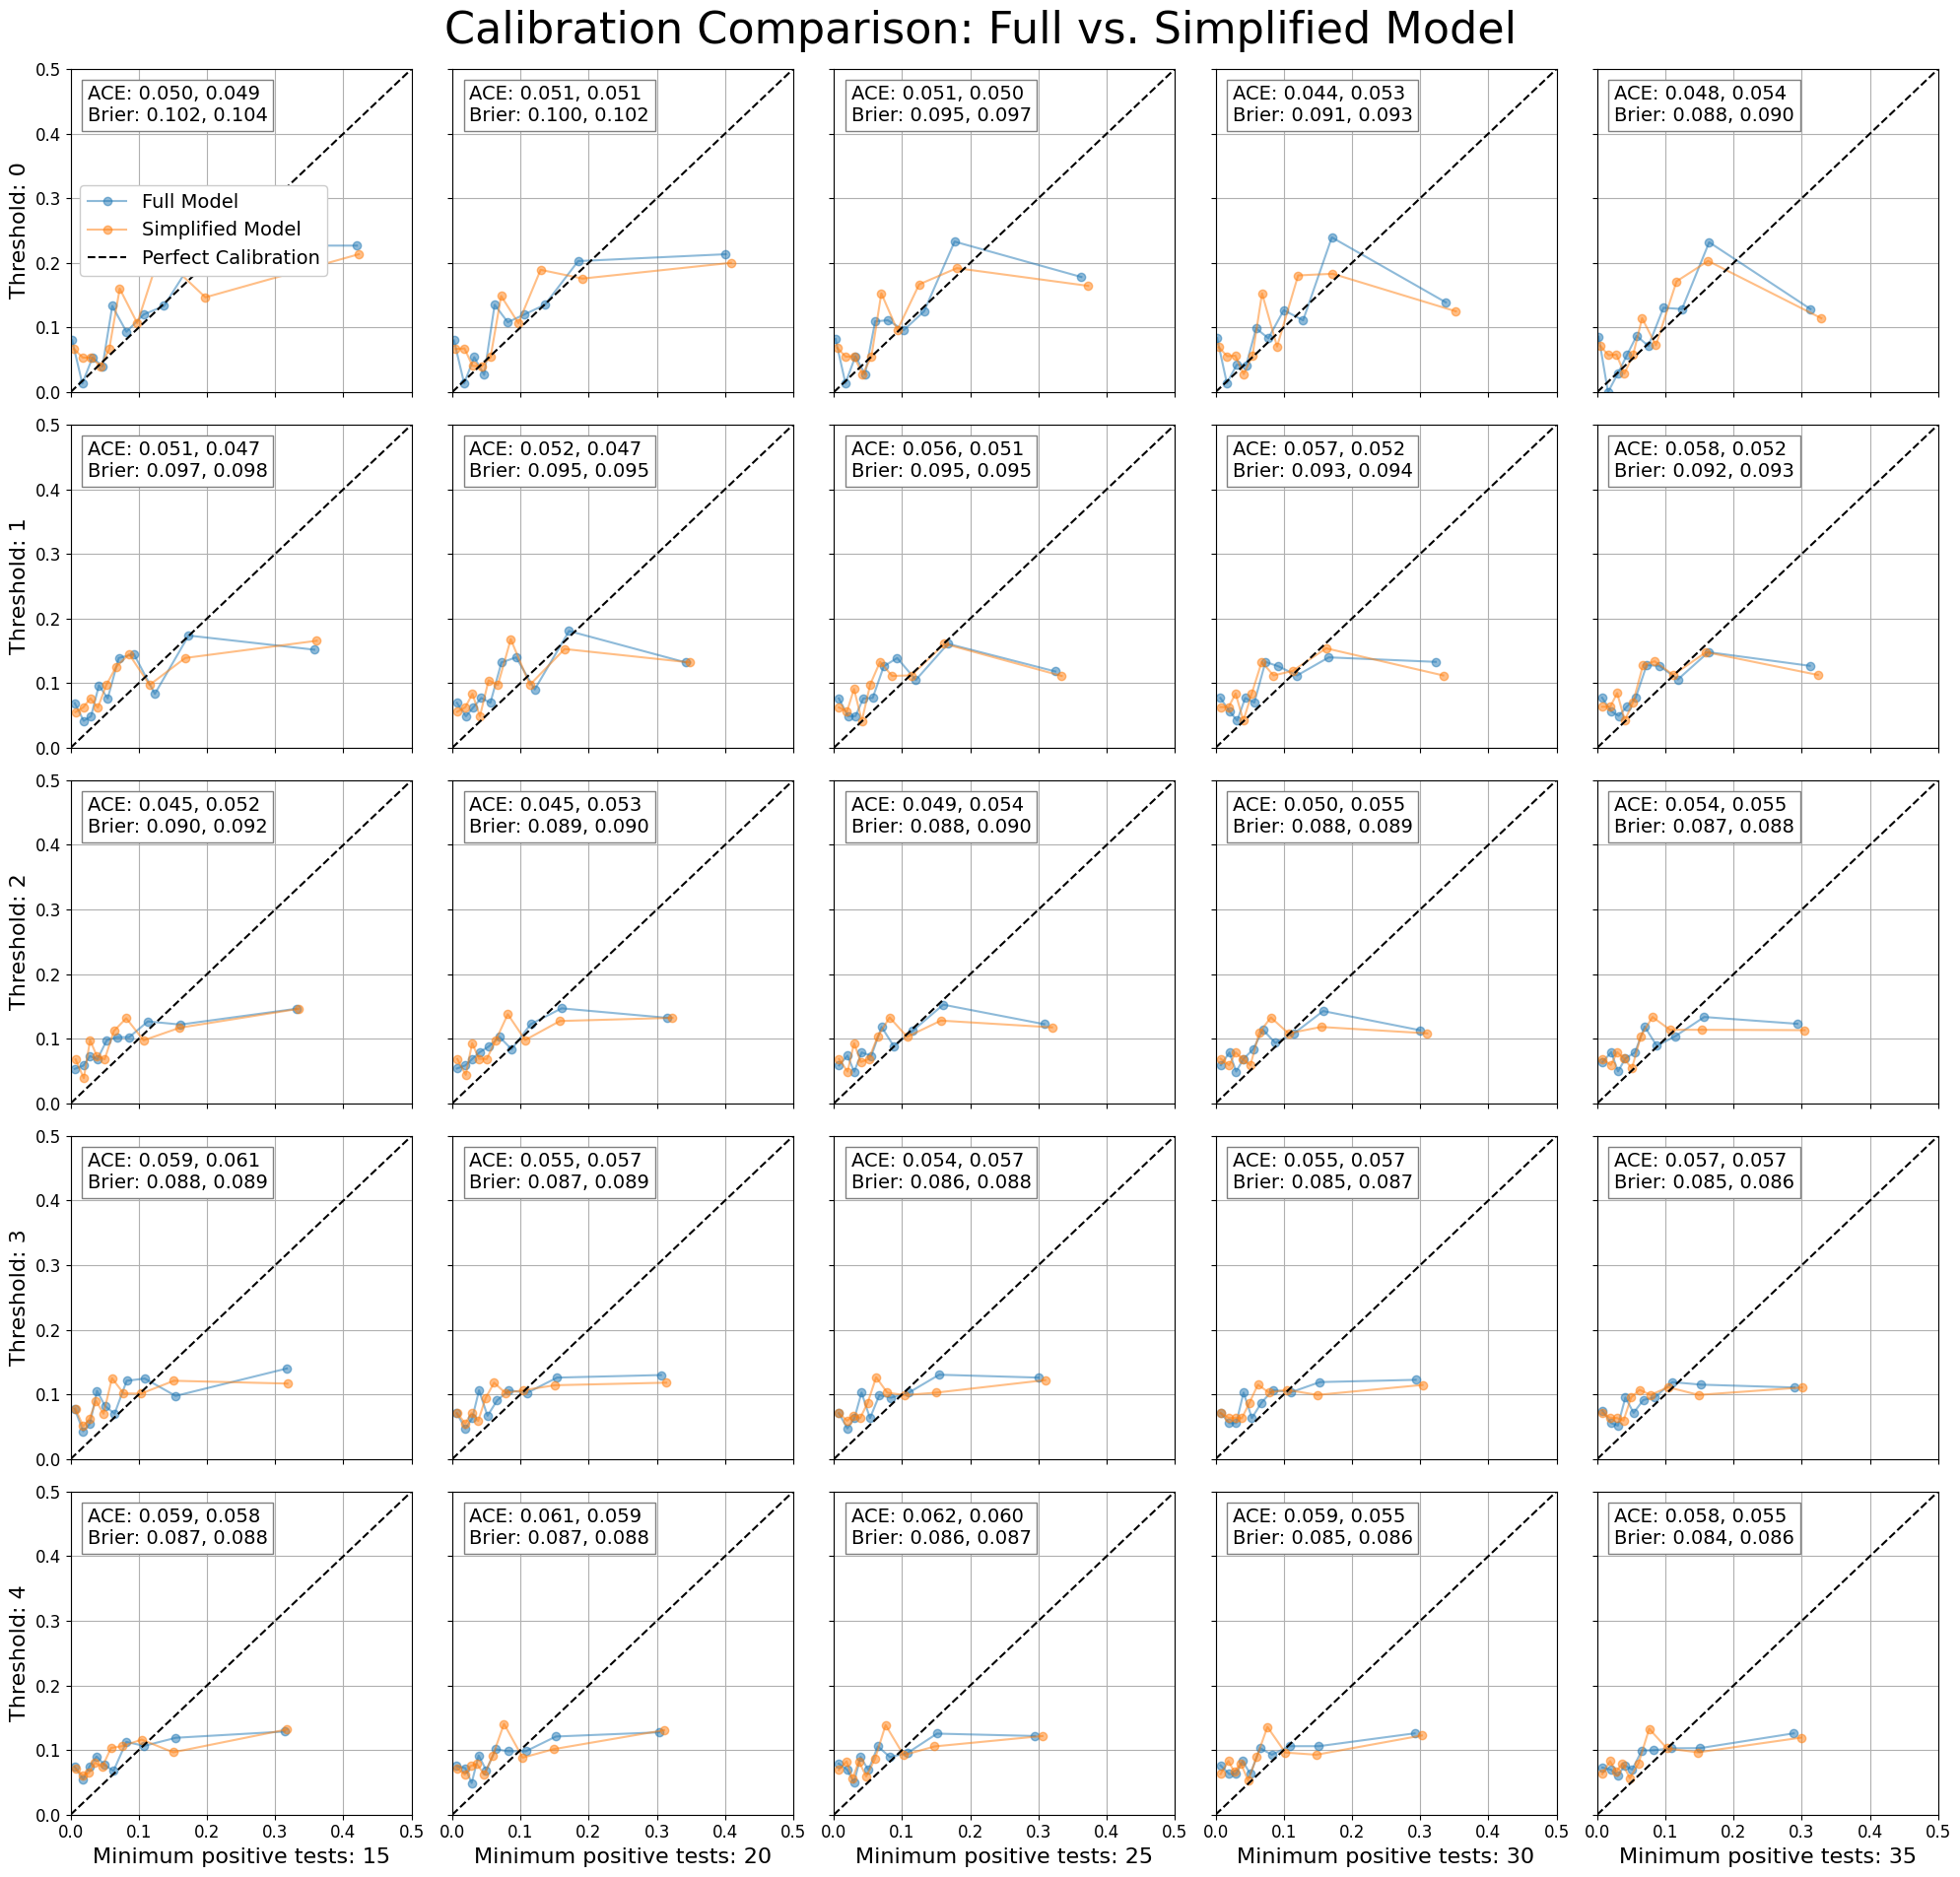

In [80]:
datasets = sorted(df_crossval_results_simple["dataset"].unique())
window_sizes = sorted(df_crossval_results_simple["window_size"].unique())

n_rows = len(datasets)
n_cols = len(window_sizes)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows), sharex=True, sharey=True)

for i, dataset in enumerate(datasets):
    for j, window_size in enumerate(window_sizes):
        ax = axes[i, j] if n_rows > 1 else axes[j]

        # Filter rows for both models
        row_orig = df_crossval_results[(df_crossval_results["dataset"] == dataset) & 
                                       (df_crossval_results["window_size"] == window_size)]
        row_simple = df_crossval_results_simple[(df_crossval_results_simple["dataset"] == dataset) & 
                                (df_crossval_results_simple["window_size"] == window_size)]

        # If neither model has data, hide the axes
        if row_orig.empty and row_simple.empty:
            ax.axis('off')
            continue

        # Plot original model (blue)
        if not row_orig.empty:
            mean_pred_orig = np.array(json.loads(row_orig.iloc[0]["mean_predicted_values"]))
            frac_pos_orig = np.array(json.loads(row_orig.iloc[0]["fraction_of_positives"]))
            ace_orig = row_orig.iloc[0]["ACE"]
            brier_orig = row_orig.iloc[0]["BrierScore"]
            ax.plot(mean_pred_orig, frac_pos_orig, "o-", color="tab:blue", label="Full Model", alpha=0.5)

        # Plot simplified model (orange)
        if not row_simple.empty:
            mean_pred_simple = np.array(json.loads(row_simple.iloc[0]["mean_predicted_values"]))
            frac_pos_simple = np.array(json.loads(row_simple.iloc[0]["fraction_of_positives"]))
            ace_simple = row_simple.iloc[0]["ACE"]
            brier_simple = row_simple.iloc[0]["BrierScore"]
            ax.plot(mean_pred_simple, frac_pos_simple, "o-", color="tab:orange", label="Simplified Model", alpha=0.5)

        # Reference line
        ax.plot([0, 1], [0, 1], "k--", label="Perfect Calibration")

        #Add annotations showing metrics for both models
        annotation_text = (
            f"ACE: {ace_orig:.3f}, {ace_simple:.3f}\n"
            f"Brier: {brier_orig:.3f}, {brier_simple:.3f}"
        )

        ax.text(0.05, 0.95, annotation_text,
                transform=ax.transAxes, fontsize=14,
                verticalalignment='top', bbox=dict(facecolor='white', alpha=1, edgecolor='gray'))
        
        if i == n_rows - 1:
            ax.set_xlabel(f"Minimum positive tests: {window_size}", fontsize=16)
        if j == 0:
            ax.set_ylabel(f"Threshold: {dataset[-1]}", fontsize=16)

        ax.set_xlim(0, 0.5)
        ax.set_ylim(0, 0.5)
        ax.tick_params(axis='both', labelsize=12)
        ax.grid(True)

        # Only show legend on the first subplot
        if i == 0 and j == 0:
            ax.legend(loc="center left", fontsize=14, framealpha=1)

plt.suptitle("Calibration Comparison: Full vs. Simplified Model", fontsize=32)
plt.tight_layout(rect=[0, 0.03, 1, 0.99])
plt.savefig("calibration_grid_combined.png", dpi=100, bbox_inches='tight')
plt.savefig("calibration_grid_combined.pdf", bbox_inches='tight')
plt.show()

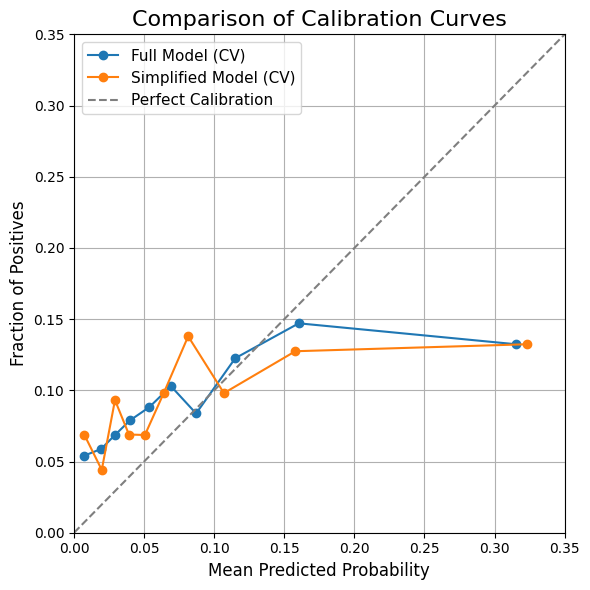

In [84]:
# Filter the data
row_orig = df_crossval_results[
    (df_crossval_results["dataset"].str.endswith("2")) & 
    (df_crossval_results["window_size"] == 20)
]

row_simple = df_crossval_results_simple[
    (df_crossval_results_simple["dataset"].str.endswith("2")) & 
    (df_crossval_results_simple["window_size"] == 20)
]

plt.figure(figsize=(6, 6))

# Plot original model (blue, circle markers)
if not row_orig.empty:
    mean_pred_orig = np.array(json.loads(row_orig.iloc[0]["mean_predicted_values"]))
    frac_pos_orig = np.array(json.loads(row_orig.iloc[0]["fraction_of_positives"]))
    plt.plot(mean_pred_orig, frac_pos_orig, "o-", color="tab:blue", 
             label="Full Model (CV)")

# Plot simplified model (orange, cross markers)
if not row_simple.empty:
    mean_pred_simple = np.array(json.loads(row_simple.iloc[0]["mean_predicted_values"]))
    frac_pos_simple = np.array(json.loads(row_simple.iloc[0]["fraction_of_positives"]))
    plt.plot(mean_pred_simple, frac_pos_simple, "o-", color="tab:orange", 
             label="Simplified Model (CV)")

# Reference line for perfect calibration
plt.plot([0, 1], [0, 1], "--", color="tab:gray", label="Perfect Calibration")

# Labels, limits, and styling
plt.xlabel("Mean Predicted Probability", size=12)
plt.ylabel("Fraction of Positives", size=12)
plt.title("Comparison of Calibration Curves", size=16)
plt.xlim(0, 0.35)
plt.ylim(0, 0.35)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()
#plt.savefig("images/simple_vs_full_calibration_curves.png", bbox_inches='tight')
plt.show()